In [ ]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [ ]:
from google.colab import drive
drive.mount('/content/gdrive')

import os
import pandas as pd

# Existing project folders
folders = [
    "/content/gdrive/MyDrive/Lucknow_Census_Raw",
    "/content/gdrive/MyDrive/lucknow_census_processed"
]

target_files = [
    "lucknow_district_prosperity_2012.csv",
    "lucknow_pincode_prosperity_2012.csv",
    "lucknow_tehsil_prosperity_2012.csv",
    "lucknow_ward_per_capita_income_2012.csv",
    "HLPCA-09157-2011_H14_census.xlsx"
]

# Locate the files
found_files = {}

for folder in folders:
    if os.path.exists(folder):
        for root, dirs, files in os.walk(folder):
            for filename in files:
                if filename in target_files:
                    found_files[filename] = os.path.join(root, filename)

print("FILE LOCATION CHECK")
print("=" * 60)

for filename in target_files:
    print(f"{filename}: {found_files.get(filename, 'NOT FOUND IN SEARCHED FOLDERS')}")

# Inspect file structure without modifying anything
print("\n\nSCHEMA AND SAMPLE DATA")
print("=" * 60)

for filename, path in found_files.items():
    print(f"\n{'=' * 60}\nFILE: {filename}")

    try:
        if filename.endswith(".csv"):
            df = pd.read_csv(path)
            print("Shape:", df.shape)
            print("Columns:", df.columns.tolist())
            print("\nData types:")
            print(df.dtypes.to_string())
            print("\nSample rows:")
            print(df.head(3).to_string(index=False))
        else:
            excel = pd.ExcelFile(path)
            print("Sheets:", excel.sheet_names)

            for sheet in excel.sheet_names:
                df = pd.read_excel(path, sheet_name=sheet, nrows=5)
                print(f"\nSheet: {sheet}")
                print("Columns:", df.columns.tolist())
                print(df.head(3).to_string(index=False))

    except Exception as e:
        print("Inspection error:", repr(e))

Mounted at /content/gdrive
FILE LOCATION CHECK
lucknow_district_prosperity_2012.csv: /content/gdrive/MyDrive/Lucknow_Census_Raw/lucknow_district_prosperity_2012.csv
lucknow_pincode_prosperity_2012.csv: /content/gdrive/MyDrive/Lucknow_Census_Raw/lucknow_pincode_prosperity_2012.csv
lucknow_tehsil_prosperity_2012.csv: /content/gdrive/MyDrive/Lucknow_Census_Raw/lucknow_tehsil_prosperity_2012.csv
lucknow_ward_per_capita_income_2012.csv: /content/gdrive/MyDrive/Lucknow_Census_Raw/lucknow_ward_per_capita_income_2012.csv
HLPCA-09157-2011_H14_census.xlsx: /content/gdrive/MyDrive/Lucknow_Census_Raw/HLPCA-09157-2011_H14_census.xlsx


SCHEMA AND SAMPLE DATA

FILE: HLPCA-09157-2011_H14_census.xlsx
Sheets: ['Sheet1', 'Sheet2', 'Sheet3']

Sheet: Sheet1
Columns: ['HOUSELISTING & HOUSING CENSUS, 2011', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13', 'Unnamed: 14', 'U

In [ ]:
import pandas as pd
import os

raw_dir = "/content/gdrive/MyDrive/Lucknow_Census_Raw"

# 1. Inspect ward income data
ward_file = os.path.join(
    raw_dir, "lucknow_ward_per_capita_income_2012.csv"
)
ward_income = pd.read_csv(ward_file)

print("=" * 65)
print("WARD INCOME VALIDATION")
print("=" * 65)

print("Rows:", len(ward_income))
print("Unique ward names:", ward_income["ward_name"].nunique())
print("Missing values:\n", ward_income.isnull().sum())
print("\nIncome summary:")
print(ward_income["per_capita_income_2012_inr"].describe())

print("\nLowest-income wards:")
print(
    ward_income.nsmallest(10, "per_capita_income_2012_inr")
    [["ward_name", "population_2012", "per_capita_income_2012_inr"]]
    .to_string(index=False)
)

print("\nHighest-income wards:")
print(
    ward_income.nlargest(10, "per_capita_income_2012_inr")
    [["ward_name", "population_2012", "per_capita_income_2012_inr"]]
    .to_string(index=False)
)

# 2. Inspect all tehsil records
tehsil_file = os.path.join(
    raw_dir, "lucknow_tehsil_prosperity_2012.csv"
)
tehsil_data = pd.read_csv(tehsil_file)

print("\n" + "=" * 65)
print("TEHSIL PROSPERITY DATA")
print("=" * 65)
print(tehsil_data.to_string(index=False))

# 3. Inspect the Census Excel file's first rows without assuming headers
census_file = os.path.join(
    raw_dir, "HLPCA-09157-2011_H14_census.xlsx"
)
raw_census = pd.read_excel(
    census_file, sheet_name="Sheet1", header=None
)

print("\n" + "=" * 65)
print("CENSUS H14 RAW STRUCTURE")
print("=" * 65)
print("Shape:", raw_census.shape)

for i in range(min(12, len(raw_census))):
    values = raw_census.iloc[i].dropna().tolist()
    print(f"\nRow {i}:")
    print(values[:35])

WARD INCOME VALIDATION
Rows: 110
Unique ward names: 110
Missing values:
 ward_name                     0
population_2012               0
prosperity_index_2012         0
per_capita_income_2012_inr    0
dtype: int64

Income summary:
count       110.000000
mean      88679.009091
std       35277.543906
min       33198.000000
25%       60098.250000
50%       84202.500000
75%      111120.000000
max      173754.000000
Name: per_capita_income_2012_inr, dtype: float64

Lowest-income wards:
                      ward_name  population_2012  per_capita_income_2012_inr
Lucknow (M Corp.) WARD NO.-0016            58496                       33198
Lucknow (M Corp.) WARD NO.-0047            32841                       40031
Lucknow (M Corp.) WARD NO.-0009            50461                       40203
Lucknow (M Corp.) WARD NO.-0085            26744                       41687
Lucknow (M Corp.) WARD NO.-0105            41620                       42136
Lucknow (M Corp.) WARD NO.-0004            25432    

In [ ]:
!pip install fiona

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 37.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [fiona]


In [ ]:
import geopandas as gpd
import os

gpkg_path = (
    "/content/gdrive/MyDrive/lucknow_census_processed/"
    "lucknow_map_boundaries_with_demographics.gpkg"
)

# List available layers
import fiona
print("Available layers:", fiona.listlayers(gpkg_path))

# Load the existing ward geography
wards_gdf = gpd.read_file(
    gpkg_path,
    layer="ward_demographics"
)

print("\nWard geography shape:", wards_gdf.shape)
print("\nColumns:")
print(wards_gdf.columns.tolist())

# Show possible ward identifiers and names
possible_cols = [
    c for c in wards_gdf.columns
    if any(k in c.lower() for k in ["ward", "name", "zone", "code", "id"])
]

print("\nPotential matching columns:")
print(wards_gdf[possible_cols].head(15).to_string(index=False))

# Check geometry and CRS
print("\nCRS:", wards_gdf.crs)
print("Missing geometries:", wards_gdf.geometry.isna().sum())
print("Empty geometries:", wards_gdf.geometry.is_empty.sum())

Available layers: ['ward_demographics']

Ward geography shape: (111, 15)

Columns:
['map_unit_id', 'map_unit_type', 'map_unit_name', 'Ward Num', 'Ward Name', 'Zone', 'households', 'total_population', 'male_population', 'female_population', 'children_0_6', 'male_children_0_6', 'female_children_0_6', 'source_census_records', 'geometry']

Potential matching columns:
map_unit_id          map_unit_name  Ward Num              Ward Name  Zone
    LMC_004   Sarojni Nagar Part 1         4   Sarojni Nagar Part 1     5
    LMC_015   Sarojni Nagar Part 2        15   Sarojni Nagar Part 2     5
    LMC_002        Raja Bijli Pasi         2        Raja Bijli Pasi     5
    LMC_021           Sharda Nagar        21           Sharda Nagar     5
    LMC_001             Ibrahimpur         1             Ibrahimpur     5
    LMC_010                Kharika        10                Kharika     5
    LMC_088          Vidyavati 1st        88          Vidyavati 1st     5
    LMC_073          Vidyavati 2nd        

In [ ]:
import pandas as pd
import geopandas as gpd
import re
import os

raw_dir = "/content/gdrive/MyDrive/Lucknow_Census_Raw"
processed_dir = "/content/gdrive/MyDrive/lucknow_census_processed"

income_path = os.path.join(
    raw_dir, "lucknow_ward_per_capita_income_2012.csv"
)

gpkg_path = os.path.join(
    processed_dir, "lucknow_map_boundaries_with_demographics.gpkg"
)

income = pd.read_csv(income_path)
wards = gpd.read_file(gpkg_path, layer="ward_demographics")

# Extract ward number from income file names
income["ward_num"] = (
    income["ward_name"]
    .str.extract(r"WARD NO\.-?0*(\d+)", flags=re.IGNORECASE)[0]
    .astype("Int64")
)

# Convert geography ward number to numeric
wards["ward_num"] = pd.to_numeric(
    wards["Ward Num"], errors="coerce"
).astype("Int64")

# Exclude the Cantonment aggregate from the municipal ward match
lmc = wards[wards["map_unit_type"].astype(str).str.contains(
    "LMC|municipal|ward", case=False, na=False
)].copy()

# If map_unit_type labels differ, retain rows with valid ward numbers 1–110
lmc = lmc[lmc["ward_num"].between(1, 110)].copy()

print("Income rows:", len(income))
print("Income rows with extracted ward number:", income["ward_num"].notna().sum())
print("Unique income ward numbers:", income["ward_num"].nunique())
print("Municipal ward boundary rows:", len(lmc))
print("Unique boundary ward numbers:", lmc["ward_num"].nunique())

# Check duplicate ward numbers before merging
print("\nDuplicate income ward numbers:")
print(income.loc[income["ward_num"].duplicated(False), ["ward_name", "ward_num"]])

print("\nDuplicate boundary ward numbers:")
print(lmc.loc[lmc["ward_num"].duplicated(False), ["Ward Name", "ward_num"]])

# One-to-one merge by ward number
matched = lmc.merge(
    income,
    on="ward_num",
    how="outer",
    indicator=True,
    validate="one_to_one"
)

print("\nMatch status:")
print(matched["_merge"].value_counts(dropna=False))

print("\nIncome records without a boundary match:")
print(
    matched.loc[matched["_merge"] == "right_only",
                ["ward_num", "ward_name"]].to_string(index=False)
)

print("\nBoundary wards without income:")
print(
    matched.loc[matched["_merge"] == "left_only",
                ["map_unit_id", "Ward Name", "ward_num"]].to_string(index=False)
)

# Inspect population differences only for matched wards
matched_rows = matched[matched["_merge"] == "both"].copy()

matched_rows["population_difference"] = (
    matched_rows["population_2012"] -
    matched_rows["total_population"]
)

print("\nMatched records:", len(matched_rows))
print("\nPopulation comparison (2012 income file vs Census 2011 boundary data):")
print(matched_rows["population_difference"].describe())

print("\nSample matches:")
print(
    matched_rows[
        ["map_unit_id", "Ward Name", "ward_num",
         "population_2012", "total_population",
         "per_capita_income_2012_inr"]
    ].head(10).to_string(index=False)
)

Income rows: 110
Income rows with extracted ward number: 110
Unique income ward numbers: 110
Municipal ward boundary rows: 110
Unique boundary ward numbers: 110

Duplicate income ward numbers:
Empty DataFrame
Columns: [ward_name, ward_num]
Index: []

Duplicate boundary ward numbers:
Empty DataFrame
Columns: [Ward Name, ward_num]
Index: []

Match status:
_merge
both          110
left_only       0
right_only      0
Name: count, dtype: int64

Income records without a boundary match:
Empty DataFrame
Columns: [ward_num, ward_name]
Index: []

Boundary wards without income:
Empty DataFrame
Columns: [map_unit_id, Ward Name, ward_num]
Index: []

Matched records: 110

Population comparison (2012 income file vs Census 2011 boundary data):
count     110.000000
mean      289.572727
std       931.358842
min      -289.000000
25%      -162.000000
50%      -114.000000
75%       264.250000
max      5091.000000
Name: population_difference, dtype: float64

Sample matches:
map_unit_id               Ward Na

In [ ]:
import os
import pandas as pd
import geopandas as gpd

raw_dir = "/content/gdrive/MyDrive/Lucknow_Census_Raw"
processed_dir = "/content/gdrive/MyDrive/lucknow_census_processed"

income_path = os.path.join(
    raw_dir, "lucknow_ward_per_capita_income_2012.csv"
)

gpkg_path = os.path.join(
    processed_dir, "lucknow_map_boundaries_with_demographics.gpkg"
)

income = pd.read_csv(income_path)
wards = gpd.read_file(gpkg_path, layer="ward_demographics")

# Extract the ward number from the income dataset
income["ward_num"] = (
    income["ward_name"]
    .str.extract(r"WARD NO\.-?0*(\d+)", flags=__import__("re").IGNORECASE)[0]
    .astype(int)
)

wards["ward_num"] = pd.to_numeric(
    wards["Ward Num"], errors="coerce"
).astype("Int64")

# Match only the 110 municipal wards
lmc = wards[wards["ward_num"].between(1, 110)].copy()

matched = lmc.merge(
    income,
    on="ward_num",
    how="inner",
    validate="one_to_one"
)

assert len(matched) == 110, "Expected 110 matched municipal wards."
assert matched["per_capita_income_2012_inr"].notna().all()

# Reverse min-max normalization: lower income = higher vulnerability
income_col = "per_capita_income_2012_inr"
income_min = matched[income_col].min()
income_max = matched[income_col].max()

matched["socioeconomic_vulnerability_score"] = (
    100 * (income_max - matched[income_col]) / (income_max - income_min)
)

matched["socioeconomic_vulnerability_score"] = (
    matched["socioeconomic_vulnerability_score"].round(2)
)

# Save a separate output
output_path = os.path.join(
    processed_dir,
    "lucknow_ward_socioeconomic_vulnerability_2012.csv"
)

output_cols = [
    "map_unit_id",
    "Ward Name",
    "ward_num",
    "population_2012",
    "per_capita_income_2012_inr",
    "prosperity_index_2012",
    "socioeconomic_vulnerability_score"
]

matched[output_cols].to_csv(output_path, index=False)

print("Saved:", output_path)
print("Matched wards:", len(matched))
print("\nVulnerability score summary:")
print(matched["socioeconomic_vulnerability_score"].describe().round(2))

print("\n10 highest-vulnerability wards:")
print(
    matched.nsmallest(10, income_col)[
        ["map_unit_id", "Ward Name", income_col,
         "socioeconomic_vulnerability_score"]
    ].to_string(index=False)
)

print("\n10 lowest-vulnerability wards:")
print(
    matched.nlargest(10, income_col)[
        ["map_unit_id", "Ward Name", income_col,
         "socioeconomic_vulnerability_score"]
    ].to_string(index=False)
)

Saved: /content/gdrive/MyDrive/lucknow_census_processed/lucknow_ward_socioeconomic_vulnerability_2012.csv
Matched wards: 110

Vulnerability score summary:
count    110.00
mean      60.53
std       25.10
min        0.00
25%       44.56
50%       63.72
75%       80.86
max      100.00
Name: socioeconomic_vulnerability_score, dtype: float64

10 highest-vulnerability wards:
map_unit_id            Ward Name  per_capita_income_2012_inr  socioeconomic_vulnerability_score
    LMC_016      Haidar Ganj 2nd                       33198                             100.00
    LMC_047       Haidarganj 1st                       40031                              95.14
    LMC_009    Kanhaiya Madhopur                       40203                              95.02
    LMC_085           Ambar Ganj                       41687                              93.96
    LMC_105       Gadi Peer Khan                       42136                              93.64
    LMC_004 Sarojni Nagar Part 1                    

In [ ]:
import pandas as pd
import os

processed_dir = "/content/gdrive/MyDrive/lucknow_census_processed"

priority_path = os.path.join(
    processed_dir,
    "lucknow_urban_healthcare_priority_scores_model_b.csv"
)

priority = pd.read_csv(priority_path)

print("Shape:", priority.shape)
print("\nColumns:")
print(priority.columns.tolist())

print("\nSample records:")
print(priority.head(5).to_string(index=False))

print("\nPriority tier distribution:")
for col in priority.columns:
    if "tier" in col.lower():
        print(f"\n{col}")
        print(priority[col].value_counts(dropna=False).to_string())

Shape: (111, 18)

Columns:
['map_unit_id', 'map_unit_type', 'map_unit_name', 'total_population', 'hospital_records', 'public_hospitals', 'private_hospitals', 'beds_total', 'nearest_hospital_distance_km', 'distance_score', 'population_score', 'bed_shortage_score', 'hospital_gap_score', 'combined_availability_gap', 'public_gap_score', 'priority_score_model_b', 'priority_rank_model_b', 'priority_tier_model_b']

Sample records:
map_unit_id map_unit_type        map_unit_name  total_population  hospital_records  public_hospitals  private_hospitals  beds_total  nearest_hospital_distance_km  distance_score  population_score  bed_shortage_score  hospital_gap_score  combined_availability_gap  public_gap_score  priority_score_model_b  priority_rank_model_b priority_tier_model_b
    LMC_045      LMC_WARD    Paper Mill Colony             29036                 0                 0                  0         0.0                      1.221805       96.396396         73.873874           79.279279       

In [ ]:
import os
import pandas as pd

processed_dir = "/content/gdrive/MyDrive/lucknow_census_processed"

priority_path = os.path.join(
    processed_dir,
    "lucknow_urban_healthcare_priority_scores_model_b.csv"
)

socio_path = os.path.join(
    processed_dir,
    "lucknow_ward_socioeconomic_vulnerability_2012.csv"
)

priority = pd.read_csv(priority_path)
socio = pd.read_csv(socio_path)

# Check unique identifiers before joining
assert priority["map_unit_id"].is_unique
assert socio["map_unit_id"].is_unique

# Join socioeconomic score onto the existing Model B data
df = priority.merge(
    socio[["map_unit_id", "socioeconomic_vulnerability_score"]],
    on="map_unit_id",
    how="left",
    validate="one_to_one"
)

# Verify coverage
print("Total urban mapping units:", len(df))
print("Units with socioeconomic scores:",
      df["socioeconomic_vulnerability_score"].notna().sum())
print("Units without socioeconomic scores:")
print(
    df.loc[df["socioeconomic_vulnerability_score"].isna(),
           ["map_unit_id", "map_unit_name", "map_unit_type"]]
    .to_string(index=False)
)

# New formula components
weights = {
    "distance_score": 0.25,
    "population_score": 0.15,
    "combined_availability_gap": 0.35,
    "public_gap_score": 0.10,
    "socioeconomic_vulnerability_score": 0.15
}

# Initialize outputs
df["priority_score_model_c"] = pd.NA
df["socioeconomic_data_status"] = "Available"

# Model C for the 110 wards with socioeconomic data
has_socio = df["socioeconomic_vulnerability_score"].notna()

df.loc[has_socio, "priority_score_model_c"] = (
    df.loc[has_socio, "distance_score"] * weights["distance_score"]
    + df.loc[has_socio, "population_score"] * weights["population_score"]
    + df.loc[has_socio, "combined_availability_gap"] * weights["combined_availability_gap"]
    + df.loc[has_socio, "public_gap_score"] * weights["public_gap_score"]
    + df.loc[has_socio, "socioeconomic_vulnerability_score"] * weights["socioeconomic_vulnerability_score"]
)

# Cantonment: no socioeconomic score available.
# Renormalize the other four weights to sum to 1.0, and flag it.
missing_socio = ~has_socio
df.loc[missing_socio, "socioeconomic_data_status"] = (
    "Missing; score excludes socioeconomic factor"
)

existing_weights_sum = (
    weights["distance_score"]
    + weights["population_score"]
    + weights["combined_availability_gap"]
    + weights["public_gap_score"]
)

df.loc[missing_socio, "priority_score_model_c"] = (
    df.loc[missing_socio, "distance_score"] * (weights["distance_score"] / existing_weights_sum)
    + df.loc[missing_socio, "population_score"] * (weights["population_score"] / existing_weights_sum)
    + df.loc[missing_socio, "combined_availability_gap"] * (weights["combined_availability_gap"] / existing_weights_sum)
    + df.loc[missing_socio, "public_gap_score"] * (weights["public_gap_score"] / existing_weights_sum)
)

# Rank and tier the new scores
df["priority_rank_model_c"] = (
    df["priority_score_model_c"]
    .rank(method="min", ascending=False)
    .astype("Int64")
)

# Apply the same tier sizes as Model B:
# 12 Very High, 22 High, 33 Moderate, 44 Lower
df = df.sort_values(
    "priority_score_model_c", ascending=False
).reset_index(drop=True)

df["priority_tier_model_c"] = "Lower"
df.loc[:11, "priority_tier_model_c"] = "Very High"
df.loc[12:33, "priority_tier_model_c"] = "High"
df.loc[34:66, "priority_tier_model_c"] = "Moderate"

# Save separately
output_path = os.path.join(
    processed_dir,
    "lucknow_urban_healthcare_priority_scores_model_c.csv"
)

df.to_csv(output_path, index=False)

print("\nSaved revised model:", output_path)
print("\nTier distribution:")
print(df["priority_tier_model_c"].value_counts())

print("\nTop 15 units:")
print(
    df[[
        "map_unit_id",
        "map_unit_name",
        "priority_score_model_c",
        "priority_tier_model_c",
        "socioeconomic_vulnerability_score",
        "socioeconomic_data_status"
    ]].head(15).to_string(index=False)
)

Total urban mapping units: 111
Units with socioeconomic scores: 110
Units without socioeconomic scores:
map_unit_id      map_unit_name        map_unit_type
 CANTONMENT Lucknow Cantonment CANTONMENT_AGGREGATE

Saved revised model: /content/gdrive/MyDrive/lucknow_census_processed/lucknow_urban_healthcare_priority_scores_model_c.csv

Tier distribution:
priority_tier_model_c
Lower        44
Moderate     33
High         22
Very High    12
Name: count, dtype: int64

Top 15 units:
map_unit_id          map_unit_name priority_score_model_c priority_tier_model_c  socioeconomic_vulnerability_score socioeconomic_data_status
    LMC_004   Sarojni Nagar Part 1               79.90873             Very High                              92.86                 Available
    LMC_085             Ambar Ganj              79.398054             Very High                              93.96                 Available
    LMC_002        Raja Bijli Pasi              78.968261             Very High                   

In [ ]:
import os
import pandas as pd

processed_dir = "/content/gdrive/MyDrive/lucknow_census_processed"

model_b_path = os.path.join(
    processed_dir,
    "lucknow_urban_healthcare_priority_scores_model_b.csv"
)

model_c_path = os.path.join(
    processed_dir,
    "lucknow_urban_healthcare_priority_scores_model_c.csv"
)

model_b = pd.read_csv(model_b_path)
model_c = pd.read_csv(model_c_path)

# Compare the 110 wards with socioeconomic data
comparison = model_b.merge(
    model_c[
        [
            "map_unit_id",
            "priority_score_model_c",
            "priority_rank_model_c",
            "priority_tier_model_c",
            "socioeconomic_vulnerability_score"
        ]
    ],
    on="map_unit_id",
    how="inner",
    validate="one_to_one"
)

# Rank and score changes
comparison["rank_change"] = (
    comparison["priority_rank_model_b"]
    - comparison["priority_rank_model_c"]
)
comparison["score_change"] = (
    comparison["priority_score_model_c"]
    - comparison["priority_score_model_b"]
)

print("Compared units:", len(comparison))

print("\nRank-change summary:")
print(comparison["rank_change"].describe().round(2))

print("\nMean absolute rank change:",
      comparison["rank_change"].abs().mean().round(2))

print("\nTier transitions (Model B -> Model C):")
print(pd.crosstab(
    comparison["priority_tier_model_b"],
    comparison["priority_tier_model_c"]
))

print("\nLargest upward priority movements:")
print(
    comparison.sort_values("rank_change", ascending=False)[
        [
            "map_unit_id", "map_unit_name",
            "priority_rank_model_b", "priority_rank_model_c",
            "rank_change", "priority_tier_model_b",
            "priority_tier_model_c",
            "socioeconomic_vulnerability_score"
        ]
    ].head(10).to_string(index=False)
)

print("\nLargest downward priority movements:")
print(
    comparison.sort_values("rank_change", ascending=True)[
        [
            "map_unit_id", "map_unit_name",
            "priority_rank_model_b", "priority_rank_model_c",
            "rank_change", "priority_tier_model_b",
            "priority_tier_model_c",
            "socioeconomic_vulnerability_score"
        ]
    ].head(10).to_string(index=False)
)

# Save comparison
comparison_path = os.path.join(
    processed_dir,
    "lucknow_urban_model_b_vs_model_c_comparison.csv"
)
comparison.to_csv(comparison_path, index=False)

print("\nComparison saved to:", comparison_path)

Compared units: 111

Rank-change summary:
count    111.00
mean      -0.06
std        7.65
min      -26.00
25%       -4.50
50%        1.00
75%        6.00
max       12.00
Name: rank_change, dtype: float64

Mean absolute rank change: 6.03

Tier transitions (Model B -> Model C):
priority_tier_model_c  High  Lower  Moderate  Very High
priority_tier_model_b                                  
High                     15      0         5          2
Lower                     0     40         4          0
Moderate                  5      4        24          0
Very High                 2      0         0         10

Largest upward priority movements:
map_unit_id           map_unit_name  priority_rank_model_b  priority_rank_model_c  rank_change priority_tier_model_b priority_tier_model_c  socioeconomic_vulnerability_score
    LMC_047          Haidarganj 1st                     93                     81           12                 Lower                 Lower                              95.14
   

In [ ]:
import os
import pandas as pd
import geopandas as gpd

raw_dir = "/content/gdrive/MyDrive/Lucknow_Census_Raw"
processed_dir = "/content/gdrive/MyDrive/lucknow_census_processed"

tehsil_path = os.path.join(
    raw_dir, "lucknow_tehsil_prosperity_2012.csv"
)

# Inspect the four supplied tehsil records
tehsil = pd.read_csv(tehsil_path)

print("Tehsil records:", len(tehsil))
print("Unique tehsil names:", tehsil["tehsil_name"].nunique())
print("\nTehsil data:")
print(tehsil.to_string(index=False))

# Inspect existing administrative geography
district_gpkg = os.path.join(
    processed_dir, "lucknow_district_analytical.gpkg"
)

print("\nAvailable GeoPackage layers:")
import fiona
print(fiona.listlayers(district_gpkg))

tehsils_gdf = gpd.read_file(
    district_gpkg, layer="tehsils_2011"
)

print("\nTehsil layer shape:", tehsils_gdf.shape)
print("Tehsil layer columns:", tehsils_gdf.columns.tolist())

print("\nTehsil layer sample:")
print(
    tehsils_gdf.drop(columns="geometry").head(10).to_string(index=False)
)

Tehsil records: 4
Unique tehsil names: 4

Tehsil data:
 tehsil_code     tehsil_name district  population_2012  prosperity_index_2012  estimated_per_capita_income_2012_inr
         819       Malihabad  Lucknow           376538                    491                                 15841
         820 Bakshi Ka Talab  Lucknow           357370                    798                                 25761
         821         Lucknow  Lucknow          3441279                   2418                                 77060
         822    Mohanlalganj  Lucknow           490077                    550                                 17759

Available GeoPackage layers:


/usr/local/lib/python3.13/dist-packages/pyogrio/raw.py:200: RuntimeWarning: Table/view villages_towns_2011_corrected is referenced in gpkg_contents, but does not exist
  return ogr_read(


['villages_towns_2011', 'tehsils_2011', 'district_boundary_2011']

Tehsil layer shape: (4, 10)
Tehsil layer columns: ['stcode11', 'dtcode11', 'sdtcode11', 'sdtname', 'Subdt_LGD', 'Dist_LGD', 'pop2011', 'tehsil_name', 'area_km2', 'geometry']

Tehsil layer sample:
stcode11 dtcode11 sdtcode11         sdtname  Subdt_LGD  Dist_LGD  pop2011     tehsil_name  area_km2
      09      157     00822    Mohanlalganj        822       162   480523    Mohanlalganj    698.10
      09      157     00820 Bakshi Ka Talab        820       162   349654 Bakshi Ka Talab    417.90
      09      157     00819       Malihabad        819       162   368453       Malihabad    474.42
      09      157     00821         Lucknow        821       162  3391208 Lucknow (Sadar)    937.67


In [ ]:
import os
import pandas as pd

processed_dir = "/content/gdrive/MyDrive/lucknow_census_processed"

print("Merged columns:")
print(merged.columns.tolist())

# Identify the correct tehsil-name column
name_candidates = [
    c for c in merged.columns
    if c == "tehsil_name" or c.startswith("tehsil_name_")
]
print("\nTehsil name candidates:", name_candidates)

# Prefer the name from the administrative boundary layer
if "tehsil_name_x" in merged.columns:
    merged["tehsil_name_final"] = merged["tehsil_name_x"]
elif "tehsil_name" in merged.columns:
    merged["tehsil_name_final"] = merged["tehsil_name"]
elif "tehsil_name_y" in merged.columns:
    merged["tehsil_name_final"] = merged["tehsil_name_y"]
else:
    raise KeyError("Could not identify a tehsil-name column.")

# Calculate the vulnerability score if not already calculated
income_col = "estimated_per_capita_income_2012_inr"

income_min = merged[income_col].min()
income_max = merged[income_col].max()

if income_max == income_min:
    raise ValueError("Income values are identical; cannot normalize.")

merged["socioeconomic_vulnerability_score"] = (
    100 * (income_max - merged[income_col]) / (income_max - income_min)
).round(2)

output_cols = [
    "tehsil_name_final",
    "tehsil_code",
    "population_2012",
    income_col,
    "prosperity_index_2012",
    "socioeconomic_vulnerability_score"
]

output = merged[output_cols].rename(
    columns={"tehsil_name_final": "tehsil_name"}
)

output_path = os.path.join(
    processed_dir,
    "lucknow_tehsil_socioeconomic_vulnerability_2012.csv"
)

output.to_csv(output_path, index=False)

print("\nSaved:", output_path)
print("\nTehsil socioeconomic vulnerability scores:")
print(
    output.sort_values(
        "socioeconomic_vulnerability_score", ascending=False
    ).to_string(index=False)
)

print("\nRows saved:", len(output))

Merged columns:
['stcode11', 'dtcode11', 'sdtcode11', 'sdtname', 'Subdt_LGD', 'Dist_LGD', 'pop2011', 'tehsil_name_x', 'area_km2', 'geometry', 'join_name', 'tehsil_code', 'tehsil_name_y', 'population_2012', 'prosperity_index_2012', 'estimated_per_capita_income_2012_inr', '_merge', 'socioeconomic_vulnerability_score']

Tehsil name candidates: ['tehsil_name_x', 'tehsil_name_y']

Saved: /content/gdrive/MyDrive/lucknow_census_processed/lucknow_tehsil_socioeconomic_vulnerability_2012.csv

Tehsil socioeconomic vulnerability scores:
    tehsil_name  tehsil_code  population_2012  estimated_per_capita_income_2012_inr  prosperity_index_2012  socioeconomic_vulnerability_score
      Malihabad          819           376538                                 15841                    491                             100.00
   Mohanlalganj          822           490077                                 17759                    550                              96.87
Bakshi Ka Talab          820           3573

In [ ]:
import os
import pandas as pd
import geopandas as gpd

processed_dir = "/content/gdrive/MyDrive/lucknow_census_processed"

# Inspect the existing settlement priority GeoPackage
gpkg_path = os.path.join(
    processed_dir,
    "lucknow_settlement_priority_mapping_popcorrected.gpkg"
)

import fiona

print("Available layers:", fiona.listlayers(gpkg_path))

settlements = gpd.read_file(
    gpkg_path,
    layer="settlement_priority"
)

print("\nShape:", settlements.shape)
print("\nColumns:")
print(settlements.columns.tolist())

print("\nSample settlements:")
print(
    settlements.drop(columns="geometry", errors="ignore")
    .head(5)
    .to_string(index=False)
)

# Check tehsil coverage
print("\nSettlement counts by tehsil:")
print(
    settlements["tehsil_name"]
    .value_counts(dropna=False)
    .to_string()
)

print("\nMissing tehsil names:", settlements["tehsil_name"].isna().sum())

Available layers: ['settlement_priority']

Shape: (819, 90)

Columns:
['pc11_s_id', 'pc11_d_id', 'pc11_sd_id', 'tehsil_name', 'pc11_tv_id', 'tv_name', 'tv_name_dir', 'is_town', 'pop2011_villagept', 'gp_code', 'gp_name', 'area_km2', 'tv_name_priority', 'tehsil_name_priority', 'is_town_priority', 'nearest_hospital_distance_km', 'nearest_hospital_record_key', 'nearest_hospital_name', 'nearest_hospital_ownership', 'nearest_hospital_beds', 'tv_name_indicator', 'tehsil_name_indicator', 'is_town_indicator', 'pop2011_villagept_priority', 'area_km2_priority', 'hospital_record_count', 'total_reported_beds', 'public_hospital_records', 'public_reported_beds', 'private_hospital_records', 'private_reported_beds', 'settlement_type', 'has_hospital_record_in_master', 'population_missing', 'area_missing', 'Primary Health Centre (Numbers)', 'Community Health Centre (Numbers)', 'Primary Heallth Sub Centre (Numbers)', 'Hospital Allopathic (Numbers)', 'town_population_from_census_csv', 'pop2011_villagept_or

In [ ]:
import os
import pandas as pd
import geopandas as gpd

processed_dir = "/content/gdrive/MyDrive/lucknow_census_processed"

settlement_path = os.path.join(
    processed_dir,
    "lucknow_settlement_priority_mapping_popcorrected.gpkg"
)

socio_path = os.path.join(
    processed_dir,
    "lucknow_tehsil_socioeconomic_vulnerability_2012.csv"
)

settlements = gpd.read_file(
    settlement_path,
    layer="settlement_priority"
)

tehsil_socio = pd.read_csv(socio_path)

# Standardize names only for joining
def normalize_name(value):
    return " ".join(str(value).strip().lower().split())

settlements["tehsil_join_key"] = (
    settlements["tehsil_name"].apply(normalize_name)
)

tehsil_socio["tehsil_join_key"] = (
    tehsil_socio["tehsil_name"].apply(normalize_name)
)

assert tehsil_socio["tehsil_join_key"].is_unique

# Join socioeconomic score to every settlement in its tehsil
joined = settlements.merge(
    tehsil_socio[
        [
            "tehsil_join_key",
            "socioeconomic_vulnerability_score",
            "estimated_per_capita_income_2012_inr"
        ]
    ],
    on="tehsil_join_key",
    how="left",
    validate="many_to_one",
    indicator=True
)

print("Total settlements:", len(joined))
print("\nJoin status:")
print(joined["_merge"].value_counts())

print("\nMissing socioeconomic scores:",
      joined["socioeconomic_vulnerability_score"].isna().sum())

print("\nSettlement counts and socioeconomic scores by tehsil:")
print(
    joined.groupby("tehsil_name").agg(
        settlements=("tv_name", "count"),
        socioeconomic_score=("socioeconomic_vulnerability_score", "first"),
        income_2012=("estimated_per_capita_income_2012_inr", "first")
    ).to_string()
)

# Verify existing formula inputs
required_cols = [
    "distance_score",
    "local_hospital_gap_score",
    "priority_score_v1"
]

print("\nExisting model fields:")
for col in required_cols:
    print(f"{col}: {'present' if col in joined.columns else 'MISSING'}")

# Save a validation copy without geometry
output_path = os.path.join(
    processed_dir,
    "lucknow_settlement_socioeconomic_join_validation.csv"
)

joined.drop(columns=["geometry"], errors="ignore").to_csv(
    output_path, index=False
)

print("\nSaved validation file:", output_path)

Total settlements: 819

Join status:
_merge
both          819
left_only       0
right_only      0
Name: count, dtype: int64

Missing socioeconomic scores: 0

Settlement counts and socioeconomic scores by tehsil:
                 settlements  socioeconomic_score  income_2012
tehsil_name                                                   
Bakshi Ka Talab          189                83.80        25761
Lucknow (Sadar)          210                 0.00        77060
Malihabad                188               100.00        15841
Mohanlalganj             232                96.87        17759

Existing model fields:
distance_score: present
local_hospital_gap_score: present
priority_score_v1: present

Saved validation file: /content/gdrive/MyDrive/lucknow_census_processed/lucknow_settlement_socioeconomic_join_validation.csv


In [ ]:
import os
import pandas as pd
import geopandas as gpd

processed_dir = "/content/gdrive/MyDrive/lucknow_census_processed"

input_path = os.path.join(
    processed_dir,
    "lucknow_settlement_socioeconomic_join_validation.csv"
)

df = pd.read_csv(input_path)

# Confirm required fields
required = [
    "distance_score",
    "local_hospital_gap_score",
    "socioeconomic_vulnerability_score",
    "priority_score_v1",
    "tv_name",
    "tehsil_name"
]

missing_cols = [c for c in required if c not in df.columns]
if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}")

# Confirm the socioeconomic join is complete
assert len(df) == 819
assert df["socioeconomic_vulnerability_score"].notna().all()

# Calculate revised rural/settlement priority score
df["priority_score_model_c"] = (
    0.51 * df["distance_score"]
    + 0.34 * df["local_hospital_gap_score"]
    + 0.15 * df["socioeconomic_vulnerability_score"]
)

# Rank settlements: 1 = highest priority
df["priority_rank_model_c"] = (
    df["priority_score_model_c"]
    .rank(method="min", ascending=False)
    .astype(int)
)

# Use the same tier counts as the existing model for comparison
df = df.sort_values(
    "priority_score_model_c",
    ascending=False
).reset_index(drop=True)

df["priority_tier_model_c"] = "Lower"
df.loc[:81, "priority_tier_model_c"] = "Very High"
df.loc[82:245, "priority_tier_model_c"] = "High"
df.loc[246:491, "priority_tier_model_c"] = "Moderate"

# Label the socioeconomic measure and its geographic limitation
df["socioeconomic_factor_level"] = "Tehsil-level proxy"
df["priority_model_version"] = "Model C: socioeconomic factor added"

output_path = os.path.join(
    processed_dir,
    "lucknow_settlement_priority_scores_model_c.csv"
)

df.to_csv(output_path, index=False)

print("Saved revised model:", output_path)
print("Total settlements:", len(df))

print("\nPriority tier distribution:")
print(df["priority_tier_model_c"].value_counts())

print("\nTop 15 settlements:")
print(
    df[[
        "tv_name",
        "tehsil_name",
        "population_corrected",
        "distance_score",
        "local_hospital_gap_score",
        "socioeconomic_vulnerability_score",
        "priority_score_v1",
        "priority_score_model_c",
        "priority_tier_model_c"
    ]].head(15).to_string(index=False)
)

Saved revised model: /content/gdrive/MyDrive/lucknow_census_processed/lucknow_settlement_priority_scores_model_c.csv
Total settlements: 819

Priority tier distribution:
priority_tier_model_c
Lower        327
Moderate     246
High         164
Very High     82
Name: count, dtype: int64

Top 15 settlements:
            tv_name  tehsil_name  population_corrected  distance_score  local_hospital_gap_score  socioeconomic_vulnerability_score  priority_score_v1  priority_score_model_c priority_tier_model_c
           Sahijana    Malihabad                2420.0      100.000000                       100                             100.00         100.000000              100.000000             Very High
     Beer Singh Pur Mohanlalganj                1592.0       95.627731                       100                              96.87          97.376638               97.300643             Very High
            Nadauli Mohanlalganj                1511.0       94.787691                       100       

In [ ]:

import pandas as pd
import numpy as np
import os

output_path = (
    "/content/gdrive/MyDrive/lucknow_census_processed/"
    "lucknow_settlement_priority_scores_model_c.csv"
)

df = pd.read_csv(output_path)

print("=== MODEL C VALIDATION ===")
print("Total rows:", len(df))
print("Duplicate settlement names within tehsil:",
      df.duplicated(subset=["tehsil_name", "tv_name"]).sum())

required_cols = [
    "distance_score",
    "local_hospital_gap_score",
    "socioeconomic_vulnerability_score",
    "priority_score_model_c"
]

print("\nMissing values:")
print(df[required_cols].isna().sum())

print("\nComponent ranges:")
print(df[required_cols].agg(["min", "max"]).T)

# Recalculate the proposed Model C formula
df["recalculated_score"] = (
    0.51 * df["distance_score"]
    + 0.34 * df["local_hospital_gap_score"]
    + 0.15 * df["socioeconomic_vulnerability_score"]
)

df["score_difference"] = (
    df["priority_score_model_c"] - df["recalculated_score"]
).abs()

print("\nMaximum absolute formula difference:",
      df["score_difference"].max())

print("\nScores outside 0–100:",
      ((df["priority_score_model_c"] < 0) |
       (df["priority_score_model_c"] > 100)).sum())

print("\nValidation complete.")


=== MODEL C VALIDATION ===
Total rows: 819
Duplicate settlement names within tehsil: 8

Missing values:
distance_score                       0
local_hospital_gap_score             0
socioeconomic_vulnerability_score    0
priority_score_model_c               0
dtype: int64

Component ranges:
                                        min    max
distance_score                     0.000000  100.0
local_hospital_gap_score           0.000000  100.0
socioeconomic_vulnerability_score  0.000000  100.0
priority_score_model_c             0.189221  100.0

Maximum absolute formula difference: 1.4210854715202004e-14

Scores outside 0–100: 0

Validation complete.


In [ ]:

import pandas as pd

path = (
    "/content/gdrive/MyDrive/lucknow_census_processed/"
    "lucknow_settlement_priority_scores_model_c.csv"
)

df = pd.read_csv(path)

duplicate_mask = df.duplicated(
    subset=["tehsil_name", "tv_name"],
    keep=False
)

duplicate_rows = df.loc[duplicate_mask].sort_values(
    ["tehsil_name", "tv_name"]
)

columns_to_show = [
    "tehsil_name",
    "tv_name",
    "population_corrected",
    "distance_score",
    "local_hospital_gap_score",
    "socioeconomic_vulnerability_score",
    "priority_score_model_c"
]

print("Duplicate rows:", len(duplicate_rows))
print("Duplicate name groups:",
      duplicate_rows.groupby(
          ["tehsil_name", "tv_name"]
      ).ngroups)

display(duplicate_rows[columns_to_show])


Duplicate rows: 16
Duplicate name groups: 8


,tehsil_name,tv_name,population_corrected,distance_score,local_hospital_gap_score,socioeconomic_vulnerability_score,priority_score_model_c
551,Bakshi Ka Talab,Misripur,1619.0,12.251130,100,83.80,52.818076
782,Bakshi Ka Talab,Misripur,4583.0,3.319133,0,83.80,14.262758
288,Bakshi Ka Talab,Tikari,1044.0,29.331143,100,83.80,61.528883
522,Bakshi Ka Talab,Tikari,1233.0,14.604625,100,83.80,54.018359
763,Lucknow (Sadar),Kakori,19403.0,3.336098,100,0.00,35.701410
790,Lucknow (Sadar),Kakori,2459.0,9.464415,0,0.00,4.826852
804,Lucknow (Sadar),Lucknow,63003.0,3.909012,0,0.00,1.993596
813,Lucknow (Sadar),Lucknow,2817105.0,2.852269,0,0.00,1.454657
683,Lucknow (Sadar),Raipur,898.0,14.620051,100,0.00,41.456226
746,Lucknow (Sadar),Raipur,3330.0,6.878900,100,0.00,37.508239


In [ ]:

import pandas as pd

path = (
    "/content/gdrive/MyDrive/lucknow_census_processed/"
    "lucknow_settlement_priority_scores_model_c.csv"
)

df = pd.read_csv(path)

duplicate_mask = df.duplicated(
    subset=["tehsil_name", "tv_name"],
    keep=False
)

duplicate_rows = df.loc[duplicate_mask].sort_values(
    ["tehsil_name", "tv_name", "population_corrected"]
)

columns = [
    "tehsil_name",
    "tv_name",
    "pc11_tv_id",
    "is_town",
    "population_corrected",
    "priority_score_v1",
    "priority_score_model_c",
    "priority_tier_model_c"
]

available_columns = [c for c in columns if c in df.columns]

display(duplicate_rows[available_columns].to_string(index=False))


'    tehsil_name  tv_name  pc11_tv_id  is_town  population_corrected  priority_score_v1  priority_score_model_c priority_tier_model_c\nBakshi Ka Talab Misripur      143275    False                1619.0          47.350678               52.818076                 Lower\nBakshi Ka Talab Misripur      143314    False                4583.0           1.991480               14.262758                 Lower\nBakshi Ka Talab   Tikari      143233    False                1044.0          57.598686               61.528883              Moderate\nBakshi Ka Talab   Tikari      143257    False                1233.0          48.762775               54.018359                 Lower\nLucknow (Sadar)   Kakori      143386    False                2459.0           5.678649                4.826852                 Lower\nLucknow (Sadar)   Kakori      800950     True               19403.0          42.001659               35.701410                 Lower\nLucknow (Sadar)  Lucknow      800952     True               6

In [ ]:

import pandas as pd

path = (
    "/content/gdrive/MyDrive/lucknow_census_processed/"
    "lucknow_settlement_priority_scores_model_c.csv"
)

df = pd.read_csv(path)

print("=== ALL TOWN RECORDS ===")

towns = df[df["is_town"] == True].copy()

cols = [
    "tehsil_name",
    "tv_name",
    "pc11_tv_id",
    "population_corrected",
    "priority_score_v1",
    "priority_score_model_c",
    "priority_tier_model_c"
]

display(
    towns[cols]
    .sort_values("population_corrected", ascending=False)
    .to_string(index=False)
)

print("\n=== LUCKNOW-NAMED RECORDS ===")

lucknow_rows = df[
    df["tv_name"].astype(str).str.contains(
        "Lucknow", case=False, na=False
    )
]

display(
    lucknow_rows[cols + ["is_town"]]
    .sort_values("population_corrected", ascending=False)
    .to_string(index=False)
)


=== ALL TOWN RECORDS ===


'    tehsil_name         tv_name  pc11_tv_id  population_corrected  priority_score_v1  priority_score_model_c priority_tier_model_c\nLucknow (Sadar)         Lucknow      800951             2817105.0           1.711361                1.454657                 Lower\nLucknow (Sadar)         Lucknow      800952               63003.0           2.345407                1.993596                 Lower\nBakshi Ka Talab Bakshi Ka Talab      800949               49166.0           5.009540               16.828109                 Lower\nLucknow (Sadar)          Kakori      800950               19403.0          42.001659               35.701410                 Lower\n      Malihabad       Malihabad      800946               17818.0           4.503553               18.828020                 Lower\n   Mohanlalganj          Amethi      800954               13530.0           3.470927               17.480788                 Lower\nLucknow (Sadar)  Kalli Pashchim      143558               12157.0          


=== LUCKNOW-NAMED RECORDS ===


'    tehsil_name tv_name  pc11_tv_id  population_corrected  priority_score_v1  priority_score_model_c priority_tier_model_c  is_town\nLucknow (Sadar) Lucknow      800951             2817105.0           1.711361                1.454657                 Lower     True\nLucknow (Sadar) Lucknow      800952               63003.0           2.345407                1.993596                 Lower     True'

In [ ]:

import os
import pandas as pd

base = "/content/gdrive/MyDrive/lucknow_census_processed"

keywords = ["town", "pca", "census", "settlement", "municipal", "cantonment"]

print("=== RELEVANT PARSED CENSUS FILES ===")

for filename in sorted(os.listdir(base)):
    if filename.lower().endswith((".csv", ".xlsx")) and any(
        word in filename.lower() for word in keywords
    ):
        print(filename)

print("\n=== CHECKING CSV FILES FOR THE TWO TOWN CODES ===")

target_codes = {"800951", "800952"}

for filename in sorted(os.listdir(base)):
    if not filename.lower().endswith(".csv"):
        continue

    path = os.path.join(base, filename)

    try:
        sample = pd.read_csv(path, nrows=5)
        columns = sample.columns.tolist()

        # Only inspect files with columns that may contain Census IDs
        id_cols = [
            col for col in columns
            if any(term in col.lower() for term in
                   ["pc11", "town_code", "town code", "town_id",
                    "geographic_id", "geo_id", "code"])
        ]

        if not id_cols:
            continue

        data = pd.read_csv(path, dtype=str)

        for col in id_cols:
            values = data[col].fillna("").str.strip()
            matches = data[
                values.isin(target_codes)
                | values.str.contains(
                    r"800951|800952", regex=True, na=False
                )
            ]

            if not matches.empty:
                print(f"\nFile: {filename}")
                print(f"Matching column: {col}")
                print("Rows found:", len(matches))
                display(matches.head(10))

    except Exception as e:
        print(f"Could not inspect {filename}: {e}")


=== RELEVANT PARSED CENSUS FILES ===
hospital_settlement_spatial_join_audit.csv
lucknow_cantonment_board_ward_pca_2011.csv
lucknow_municipal_corporation_ward_pca_2011.csv
lucknow_settlement_access_indicators_osm_v1.csv
lucknow_settlement_access_indicators_v1.csv
lucknow_settlement_distance_blended_manual_v1.csv
lucknow_settlement_graph_snapping.csv
lucknow_settlement_healthcare_indicators_v1.csv
lucknow_settlement_healthcare_indicators_v2.csv
lucknow_settlement_healthcare_indicators_v3.csv
lucknow_settlement_healthcare_integrated.csv
lucknow_settlement_healthcare_integrated_popcorrected.csv
lucknow_settlement_healthcare_integrated_popcorrected_v2.csv
lucknow_settlement_hospital_summary.csv
lucknow_settlement_nearest_hospital_access.csv
lucknow_settlement_priority_scores_model_c.csv
lucknow_settlement_priority_scores_v1.csv
lucknow_settlement_road_distance_v1.csv
lucknow_settlement_road_origin_diagnostic.csv
lucknow_settlement_road_origin_graph_validation.csv
lucknow_settlement_score_co

,town_code,town_name,geographic_id,ward_code,households,total_population,male_population,female_population,children_0_6,male_children_0_6,female_children_0_6,census_year,source_pdf_page,source_town_code
0,800952,Lucknow Cantonment Board,800952_0001,0001,1339,14990,12044,2946,588,310,278,2011,325,800952
1,800952,Lucknow Cantonment Board,800952_0002,0002,3007,12273,6214,6059,1892,1032,860,2011,325,800952
2,800952,Lucknow Cantonment Board,800952_0003,0003,830,3455,1771,1684,408,220,188,2011,325,800952
3,800952,Lucknow Cantonment Board,800952_0004,0004,1207,5358,2722,2636,540,289,251,2011,325,800952
4,800952,Lucknow Cantonment Board,800952_0005,0005,851,4193,2172,2021,359,185,174,2011,325,800952
5,800952,Lucknow Cantonment Board,800952_0006,0006,1390,7218,3665,3553,770,386,384,2011,325,800952
6,800952,Lucknow Cantonment Board,800952_0007,0007,1270,7173,3705,3468,717,383,334,2011,325,800952
7,800952,Lucknow Cantonment Board,800952_0008,0008,1665,8343,4293,4050,921,479,442,2011,325,800952



File: lucknow_cantonment_board_ward_pca_2011.csv
Matching column: geographic_id
Rows found: 8


,town_code,town_name,geographic_id,ward_code,households,total_population,male_population,female_population,children_0_6,male_children_0_6,female_children_0_6,census_year,source_pdf_page,source_town_code
0,800952,Lucknow Cantonment Board,800952_0001,0001,1339,14990,12044,2946,588,310,278,2011,325,800952
1,800952,Lucknow Cantonment Board,800952_0002,0002,3007,12273,6214,6059,1892,1032,860,2011,325,800952
2,800952,Lucknow Cantonment Board,800952_0003,0003,830,3455,1771,1684,408,220,188,2011,325,800952
3,800952,Lucknow Cantonment Board,800952_0004,0004,1207,5358,2722,2636,540,289,251,2011,325,800952
4,800952,Lucknow Cantonment Board,800952_0005,0005,851,4193,2172,2021,359,185,174,2011,325,800952
5,800952,Lucknow Cantonment Board,800952_0006,0006,1390,7218,3665,3553,770,386,384,2011,325,800952
6,800952,Lucknow Cantonment Board,800952_0007,0007,1270,7173,3705,3468,717,383,334,2011,325,800952
7,800952,Lucknow Cantonment Board,800952_0008,0008,1665,8343,4293,4050,921,479,442,2011,325,800952



File: lucknow_cantonment_board_ward_pca_2011.csv
Matching column: source_town_code
Rows found: 8


,town_code,town_name,geographic_id,ward_code,households,total_population,male_population,female_population,children_0_6,male_children_0_6,female_children_0_6,census_year,source_pdf_page,source_town_code
0,800952,Lucknow Cantonment Board,800952_0001,0001,1339,14990,12044,2946,588,310,278,2011,325,800952
1,800952,Lucknow Cantonment Board,800952_0002,0002,3007,12273,6214,6059,1892,1032,860,2011,325,800952
2,800952,Lucknow Cantonment Board,800952_0003,0003,830,3455,1771,1684,408,220,188,2011,325,800952
3,800952,Lucknow Cantonment Board,800952_0004,0004,1207,5358,2722,2636,540,289,251,2011,325,800952
4,800952,Lucknow Cantonment Board,800952_0005,0005,851,4193,2172,2021,359,185,174,2011,325,800952
5,800952,Lucknow Cantonment Board,800952_0006,0006,1390,7218,3665,3553,770,386,384,2011,325,800952
6,800952,Lucknow Cantonment Board,800952_0007,0007,1270,7173,3705,3468,717,383,334,2011,325,800952
7,800952,Lucknow Cantonment Board,800952_0008,0008,1665,8343,4293,4050,921,479,442,2011,325,800952


... (72 outputs left out)


File: slum_data_lucknow.csv
Matching column: Town Code
Rows found: 1


,State Code,State Name,District Code,District Name,Sub District Code,Sub District Name,Town Code,Town Name,Total Population of Town,Town Class,...,System of Drainage Open-1/Closed-2/Both-3/No-4 ?,Private Latrines-Pit (Number),Private Latrines-Flush/Pour Flush (Number),Private Latrines-Service (Number),Private Latrines-Others (Number),Private Latrines-Community (Number),No. of Tap points/Public Hydtrants installed for Protected Water Supply,Electricity-Domestic Connection (Numbers),Electricity-Road Lighting Connection (Numbers),Electricity-Others Connection (Numbers)
2,09,UTTAR PRADESH,157,Lucknow,00821,Lucknow,800951,Lucknow (M Corp.),2817105,I,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



File: town_data_lucknow.csv
Matching column: Town Code
Rows found: 2


,State Code,State Name,District Code,District Name,Sub District Code,Sub District Name,Town Code,Town Name,Total Households,Total Population of Town,...,Nearest Village/Town Name.33,Nearest Village/Town Distance (in kms.).32,Manufactured Commodity (First)\n,Manufactured Commodity (Second),Manufactured Commodity (Third),Nationalised Bank (Numbers),Private Commercial Bank (Numbers),Co-operative Bank (Numbers),Agricultural Credit Society (Numbers),Non-Agricultural Credit Society (Numbers)
7,09,UTTAR PRADESH,157,LUCKNOW,00821,LUCKNOW,800951,Lucknow (M Corp.),538149,2817105,...,NaN,NaN,NaN,ZARDOZI,SWEETS,25,14,16,82,0
8,09,UTTAR PRADESH,157,LUCKNOW,00821,LUCKNOW,800952,Lucknow (CB),11559,63003,...,NaN,NaN,CHIKAN WORKS,NaN,NaN,7,2,1,0,0


In [ ]:

import os
import pandas as pd

base_dir = "/content/gdrive/MyDrive/lucknow_census_processed"
file_path = os.path.join(
    base_dir,
    "lucknow_settlement_priority_scores_model_c.csv"
)

if os.path.exists(file_path):
    df = pd.read_csv(file_path)

    print("Model C file already exists.")
    print("Shape:", df.shape)
    print("\nColumns:")
    print(df.columns.tolist())

    print("\nFirst 5 rows:")
    display(df.head())

    print("\nPriority tier distribution:")
    tier_col = next(
        (c for c in df.columns
         if "tier" in c.lower()),
        None
    )

    if tier_col:
        display(df[tier_col].value_counts(dropna=False))
    else:
        print("No priority-tier column found.")
else:
    print("Model C file does not exist yet.")
    print("We will generate it using the agreed formula.")


Model C file already exists.
Shape: (819, 98)

Columns:
['pc11_s_id', 'pc11_d_id', 'pc11_sd_id', 'tehsil_name', 'pc11_tv_id', 'tv_name', 'tv_name_dir', 'is_town', 'pop2011_villagept', 'gp_code', 'gp_name', 'area_km2', 'tv_name_priority', 'tehsil_name_priority', 'is_town_priority', 'nearest_hospital_distance_km', 'nearest_hospital_record_key', 'nearest_hospital_name', 'nearest_hospital_ownership', 'nearest_hospital_beds', 'tv_name_indicator', 'tehsil_name_indicator', 'is_town_indicator', 'pop2011_villagept_priority', 'area_km2_priority', 'hospital_record_count', 'total_reported_beds', 'public_hospital_records', 'public_reported_beds', 'private_hospital_records', 'private_reported_beds', 'settlement_type', 'has_hospital_record_in_master', 'population_missing', 'area_missing', 'Primary Health Centre (Numbers)', 'Community Health Centre (Numbers)', 'Primary Heallth Sub Centre (Numbers)', 'Hospital Allopathic (Numbers)', 'town_population_from_census_csv', 'pop2011_villagept_original', 'vill

,pc11_s_id,pc11_d_id,pc11_sd_id,tehsil_name,pc11_tv_id,tv_name,tv_name_dir,is_town,pop2011_villagept,gp_code,...,population_exposure_score,tehsil_join_key,socioeconomic_vulnerability_score,estimated_per_capita_income_2012_inr,_merge,priority_score_model_c,priority_rank_model_c,priority_tier_model_c,socioeconomic_factor_level,priority_model_version
0,9,157,819,Malihabad,143067,Sahijana,Sahijana,False,2420.0,75698.0,...,73.865031,malihabad,100.00,15841,both,100.000000,1,Very High,Tehsil-level proxy,Model C: socioeconomic factor added
1,9,157,822,Mohanlalganj,143745,Beer Singh Pur,Beer Singh Pur,False,1592.0,75712.0,...,55.950920,mohanlalganj,96.87,17759,both,97.300643,2,Very High,Tehsil-level proxy,Model C: socioeconomic factor added
2,9,157,822,Mohanlalganj,143781,Nadauli,Nadauli,False,1511.0,75766.0,...,52.944785,mohanlalganj,96.87,17759,both,96.872223,3,Very High,Tehsil-level proxy,Model C: socioeconomic factor added
3,9,157,822,Mohanlalganj,143774,Adhaeya,Adhaeya,False,1056.0,75735.0,...,34.601227,mohanlalganj,96.87,17759,both,95.978754,4,Very High,Tehsil-level proxy,Model C: socioeconomic factor added
4,9,157,822,Mohanlalganj,143780,Bhatwara,Bhatwara,False,603.0,265363.0,...,13.865031,mohanlalganj,96.87,17759,both,94.787965,5,Very High,Tehsil-level proxy,Model C: socioeconomic factor added



Priority tier distribution:


,count
priority_tier_v1,
High preliminary priority,470
Moderate preliminary priority,239
Very high preliminary priority,58
Lower preliminary priority,52


In [ ]:

import os
import pandas as pd

base_dir = "/content/gdrive/MyDrive/lucknow_census_processed"
file_path = os.path.join(
    base_dir,
    "lucknow_settlement_priority_scores_model_c.csv"
)

df = pd.read_csv(file_path)

print("Total settlements:", len(df))
print("Unique settlement IDs:", df["pc11_tv_id"].nunique())

print("\n=== MODEL C PRIORITY TIER DISTRIBUTION ===")
print(
    df["priority_tier_model_c"]
    .value_counts(dropna=False)
    .to_string()
)

print("\n=== MODEL C SCORE SUMMARY ===")
print(
    df["priority_score_model_c"]
    .describe()
    .round(2)
    .to_string()
)

print("\n=== TOP 15 MODEL C PRIORITY SETTLEMENTS ===")
cols = [
    "pc11_tv_id",
    "tv_name",
    "tehsil_name",
    "is_town",
    "population_corrected",
    "nearest_hospital_distance_km",
    "hospital_record_count",
    "distance_score",
    "local_hospital_gap_score",
    "socioeconomic_vulnerability_score",
    "priority_score_model_c",
    "priority_rank_model_c",
    "priority_tier_model_c"
]

display(
    df.sort_values("priority_rank_model_c")[cols]
      .head(15)
      .reset_index(drop=True)
)


Total settlements: 819
Unique settlement IDs: 819

=== MODEL C PRIORITY TIER DISTRIBUTION ===
priority_tier_model_c
Lower        327
Moderate     246
High         164
Very High     82

=== MODEL C SCORE SUMMARY ===
count    819.00
mean      55.81
std       17.63
min        0.19
25%       48.88
50%       57.70
75%       65.62
max      100.00

=== TOP 15 MODEL C PRIORITY SETTLEMENTS ===


,pc11_tv_id,tv_name,tehsil_name,is_town,population_corrected,nearest_hospital_distance_km,hospital_record_count,distance_score,local_hospital_gap_score,socioeconomic_vulnerability_score,priority_score_model_c,priority_rank_model_c,priority_tier_model_c
0,143067,Sahijana,Malihabad,False,2420.0,15.971042,0,100.000000,100,100.00,100.000000,1,Very High
1,143745,Beer Singh Pur,Mohanlalganj,False,1592.0,15.278022,0,95.627731,100,96.87,97.300643,2,Very High
2,143781,Nadauli,Mohanlalganj,False,1511.0,15.144872,0,94.787691,100,96.87,96.872223,3,Very High
3,143774,Adhaeya,Mohanlalganj,False,1056.0,14.867190,0,93.035792,100,96.87,95.978754,4,Very High
4,143780,Bhatwara,Mohanlalganj,False,603.0,14.497103,0,90.700913,100,96.87,94.787965,5,Very High
5,143782,Khuddi Khera,Mohanlalganj,False,488.0,14.456696,0,90.445988,100,96.87,94.657954,6,Very High
6,143744,Rati,Mohanlalganj,False,2190.0,14.366507,0,89.876986,100,96.87,94.367763,7,Very High
7,143068,Rusena,Malihabad,False,4615.0,14.105066,0,88.227552,100,100.00,93.996051,8,Very High
8,143742,Raghunath Khera,Mohanlalganj,False,1688.0,13.919676,0,87.057924,100,96.87,92.930041,9,Very High
9,143775,Harihar Pur Par--Sa,Mohanlalganj,False,669.0,13.721928,0,85.810335,100,96.87,92.293771,10,Very High


In [ ]:

import pandas as pd
from scipy.stats import spearmanr

file_path = (
    "/content/gdrive/MyDrive/lucknow_census_processed/"
    "lucknow_settlement_priority_scores_model_c.csv"
)

df = pd.read_csv(file_path)

# Compare the original and socioeconomic-enhanced rankings
df["rank_change"] = (
    df["priority_rank_v1"] - df["priority_rank_model_c"]
)

print("=== MODEL V1 VS MODEL C ===")
print("Settlements compared:", len(df))
print(
    "Spearman rank correlation:",
    round(
        spearmanr(
            df["priority_rank_v1"],
            df["priority_rank_model_c"]
        ).statistic,
        4
    )
)
print(
    "Mean absolute rank change:",
    round(df["rank_change"].abs().mean(), 2)
)
print(
    "Settlements moving up in priority:",
    int((df["rank_change"] > 0).sum())
)
print(
    "Settlements moving down in priority:",
    int((df["rank_change"] < 0).sum())
)
print(
    "Settlements with unchanged rank:",
    int((df["rank_change"] == 0).sum())
)

print("\n=== LARGEST UPWARD MOVEMENTS ===")
display(
    df.sort_values("rank_change", ascending=False)[
        [
            "tv_name", "tehsil_name",
            "priority_rank_v1", "priority_rank_model_c",
            "rank_change", "socioeconomic_vulnerability_score",
            "priority_score_v1", "priority_score_model_c"
        ]
    ].head(10).reset_index(drop=True)
)

print("\n=== LARGEST DOWNWARD MOVEMENTS ===")
display(
    df.sort_values("rank_change", ascending=True)[
        [
            "tv_name", "tehsil_name",
            "priority_rank_v1", "priority_rank_model_c",
            "rank_change", "socioeconomic_vulnerability_score",
            "priority_score_v1", "priority_score_model_c"
        ]
    ].head(10).reset_index(drop=True)
)


=== MODEL V1 VS MODEL C ===
Settlements compared: 819
Spearman rank correlation: 0.8941
Mean absolute rank change: 69.86
Settlements moving up in priority: 494
Settlements moving down in priority: 282
Settlements with unchanged rank: 43

=== LARGEST UPWARD MOVEMENTS ===


,tv_name,tehsil_name,priority_rank_v1,priority_rank_model_c,rank_change,socioeconomic_vulnerability_score,priority_score_v1,priority_score_model_c
0,Garhi Sajar Khan,Malihabad,729,562,167,100.0,44.040152,52.434129
1,Gagan Barauli,Malihabad,731,564,167,100.0,43.928503,52.339228
2,Meethenagar,Malihabad,727,561,166,100.0,44.085267,52.472477
3,Shivdaspur,Malihabad,762,597,165,100.0,41.869808,50.589337
4,Firozpur,Malihabad,710,546,164,100.0,44.674031,52.972926
5,Naru,Malihabad,765,601,164,100.0,41.578959,50.342115
6,Tikari Khurd,Malihabad,732,570,162,100.0,43.818580,52.245793
7,Vidhishyama,Malihabad,703,542,161,100.0,44.888583,53.155296
8,Fatehnagar,Malihabad,714,554,160,100.0,44.429594,52.765155
9,Ram Nagar,Malihabad,742,582,160,100.0,43.060171,51.601146



=== LARGEST DOWNWARD MOVEMENTS ===


,tv_name,tehsil_name,priority_rank_v1,priority_rank_model_c,rank_change,socioeconomic_vulnerability_score,priority_score_v1,priority_score_model_c
0,Kusmi,Lucknow (Sadar),211,575,-364,0.0,61.347523,52.145395
1,Bhagu Khera,Lucknow (Sadar),190,549,-359,0.0,62.217601,52.884961
2,Ratoli,Lucknow (Sadar),209,568,-359,0.0,61.483890,52.261307
3,Shahpur,Lucknow (Sadar),186,545,-359,0.0,62.473877,53.102796
4,Godoli,Lucknow (Sadar),208,566,-358,0.0,61.526798,52.297779
5,Memora,Lucknow (Sadar),172,529,-357,0.0,63.339731,53.838772
6,Dariyapur,Lucknow (Sadar),178,535,-357,0.0,62.870755,53.440142
7,Padra Thavar,Lucknow (Sadar),184,541,-357,0.0,62.537077,53.156515
8,Adampur Indwara,Lucknow (Sadar),171,527,-356,0.0,63.409014,53.897662
9,Thavar,Lucknow (Sadar),230,586,-356,0.0,60.271422,51.230709


In [ ]:

import pandas as pd

file_path = (
    "/content/gdrive/MyDrive/lucknow_census_processed/"
    "lucknow_settlement_priority_scores_model_c.csv"
)

df = pd.read_csv(file_path)

tehsil_summary = (
    df.groupby("tehsil_name", dropna=False)
      .agg(
          settlements=("pc11_tv_id", "count"),
          mean_vulnerability=(
              "socioeconomic_vulnerability_score", "mean"
          ),
          mean_original_score=("priority_score_v1", "mean"),
          mean_model_c_score=("priority_score_model_c", "mean"),
          mean_original_rank=("priority_rank_v1", "mean"),
          mean_model_c_rank=("priority_rank_model_c", "mean"),
          very_high_count=(
              "priority_tier_model_c",
              lambda s: (s == "Very High").sum()
          )
      )
      .reset_index()
)

tehsil_summary["mean_rank_change"] = (
    tehsil_summary["mean_original_rank"]
    - tehsil_summary["mean_model_c_rank"]
)

print("=== MODEL C IMPACT BY TEHSIL ===")
display(
    tehsil_summary.round(2).sort_values(
        "mean_model_c_rank"
    ).reset_index(drop=True)
)


=== MODEL C IMPACT BY TEHSIL ===


,tehsil_name,settlements,mean_vulnerability,mean_original_score,mean_model_c_score,mean_original_rank,mean_model_c_rank,very_high_count,mean_rank_change
0,Mohanlalganj,232,96.87,60.19,65.70,300.88,255.22,52,45.66
1,Malihabad,188,100.00,58.90,65.06,327.25,265.06,30,62.19
2,Bakshi Ka Talab,189,83.80,49.73,54.84,470.10,438.87,0,31.22
3,Lucknow (Sadar),210,0.00,44.07,37.46,550.55,684.77,0,-134.22


In [ ]:

import pandas as pd

file_path = (
    "/content/gdrive/MyDrive/lucknow_census_processed/"
    "lucknow_settlement_priority_scores_model_c.csv"
)

df = pd.read_csv(file_path)

print("=== SCORE AND RANK BOUNDARIES BY MODEL C TIER ===")

tier_summary = (
    df.groupby("priority_tier_model_c", dropna=False)
      .agg(
          settlements=("pc11_tv_id", "count"),
          best_rank=("priority_rank_model_c", "min"),
          worst_rank=("priority_rank_model_c", "max"),
          minimum_score=("priority_score_model_c", "min"),
          maximum_score=("priority_score_model_c", "max"),
          mean_score=("priority_score_model_c", "mean")
      )
      .sort_values("best_rank")
      .round(3)
)

display(tier_summary)

print("\n=== FIRST AND LAST 5 RANKS ===")
display(
    pd.concat([
        df.nsmallest(5, "priority_rank_model_c"),
        df.nlargest(5, "priority_rank_model_c")
    ])[
        [
            "tv_name",
            "tehsil_name",
            "priority_score_model_c",
            "priority_rank_model_c",
            "priority_tier_model_c"
        ]
    ].reset_index(drop=True)
)


=== SCORE AND RANK BOUNDARIES BY MODEL C TIER ===


,settlements,best_rank,worst_rank,minimum_score,maximum_score,mean_score
priority_tier_model_c,,,,,,
Very High,82,1,82,74.845,100.000,83.326
High,164,83,246,63.432,74.841,68.389
Moderate,246,247,492,54.944,63.383,58.912
Lower,327,493,819,0.189,54.930,40.258



=== FIRST AND LAST 5 RANKS ===


,tv_name,tehsil_name,priority_score_model_c,priority_rank_model_c,priority_tier_model_c
0,Sahijana,Malihabad,100.000000,1,Very High
1,Beer Singh Pur,Mohanlalganj,97.300643,2,Very High
2,Nadauli,Mohanlalganj,96.872223,3,Very High
3,Adhaeya,Mohanlalganj,95.978754,4,Very High
4,Bhatwara,Mohanlalganj,94.787965,5,Very High
5,Malesemau,Lucknow (Sadar),0.189221,819,Lower
6,Mutkkipur,Lucknow (Sadar),0.620772,818,Lower
7,Kushmora Dhaluapur,Lucknow (Sadar),1.120813,817,Lower
8,Bijnor,Lucknow (Sadar),1.340720,816,Lower
9,Anora Kala,Lucknow (Sadar),1.389731,815,Lower


In [ ]:

import geopandas as gpd
import os

gpkg_path = (
    "/content/gdrive/MyDrive/lucknow_census_processed/"
    "lucknow_settlement_priority_mapping_popcorrected.gpkg"
)

print("GeoPackage exists:", os.path.exists(gpkg_path))

if os.path.exists(gpkg_path):
    layers = gpd.list_layers(gpkg_path)
    print("\nAvailable layers:")
    display(layers)

    layer_name = "settlement_priority"
    gdf = gpd.read_file(gpkg_path, layer=layer_name)

    print("\nLayer:", layer_name)
    print("Shape:", gdf.shape)
    print("CRS:", gdf.crs)

    model_c_cols = [
        c for c in gdf.columns
        if "model_c" in c.lower()
        or "socioeconomic_vulnerability" in c.lower()
    ]

    print("\nModel C-related columns already present:")
    print(model_c_cols)

    print("\nSample columns:")
    print(gdf.columns.tolist()[:20])
else:
    print("GeoPackage not found at the expected path.")


GeoPackage exists: True

Available layers:


,name,geometry_type
0,settlement_priority,Polygon



Layer: settlement_priority
Shape: (819, 90)
CRS: GEOGCS["WGS 84 (CRS84)",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Longitude",EAST],AXIS["Latitude",NORTH],AUTHORITY["OGC","CRS84"]]

Model C-related columns already present:
[]

Sample columns:
['pc11_s_id', 'pc11_d_id', 'pc11_sd_id', 'tehsil_name', 'pc11_tv_id', 'tv_name', 'tv_name_dir', 'is_town', 'pop2011_villagept', 'gp_code', 'gp_name', 'area_km2', 'tv_name_priority', 'tehsil_name_priority', 'is_town_priority', 'nearest_hospital_distance_km', 'nearest_hospital_record_key', 'nearest_hospital_name', 'nearest_hospital_ownership', 'nearest_hospital_beds']


In [ ]:

import os
import pandas as pd
import geopandas as gpd

base_dir = "/content/gdrive/MyDrive/lucknow_census_processed"

gpkg_path = os.path.join(
    base_dir,
    "lucknow_settlement_priority_mapping_popcorrected.gpkg"
)

model_c_path = os.path.join(
    base_dir,
    "lucknow_settlement_priority_scores_model_c.csv"
)

# Load existing polygons and Model C scores
gdf = gpd.read_file(
    gpkg_path,
    layer="settlement_priority"
)

model_c = pd.read_csv(model_c_path)

# Standardize join-key types
gdf["pc11_tv_id"] = pd.to_numeric(
    gdf["pc11_tv_id"], errors="coerce"
).astype("Int64")

model_c["pc11_tv_id"] = pd.to_numeric(
    model_c["pc11_tv_id"], errors="coerce"
).astype("Int64")

# Select only the Model C attributes needed for mapping
score_cols = [
    "pc11_tv_id",
    "socioeconomic_vulnerability_score",
    "estimated_per_capita_income_2012_inr",
    "priority_score_model_c",
    "priority_rank_model_c",
    "priority_tier_model_c",
    "priority_model_version",
    "socioeconomic_factor_level"
]

scores = model_c[score_cols].copy()

print("Polygon rows:", len(gdf))
print("Model C score rows:", len(scores))
print("Unique polygon IDs:", gdf["pc11_tv_id"].nunique())
print("Unique score IDs:", scores["pc11_tv_id"].nunique())

# Ensure the score table has one row per settlement
if scores["pc11_tv_id"].duplicated().any():
    raise ValueError("Duplicate settlement IDs in Model C score file.")

# Join scores to the existing polygons
gdf_model_c = gdf.merge(
    scores,
    on="pc11_tv_id",
    how="left",
    validate="one_to_one",
    indicator=True
)

print("\n=== JOIN VALIDATION ===")
print(gdf_model_c["_merge"].value_counts(dropna=False))
print(
    "Missing Model C scores:",
    gdf_model_c["priority_score_model_c"].isna().sum()
)
print(
    "Missing Model C tiers:",
    gdf_model_c["priority_tier_model_c"].isna().sum()
)

print("\nSample joined records:")
display(
    gdf_model_c[
        [
            "tv_name",
            "pc11_tv_id",
            "tehsil_name",
            "priority_score_model_c",
            "priority_rank_model_c",
            "priority_tier_model_c"
        ]
    ].head()
)


Polygon rows: 819
Model C score rows: 819
Unique polygon IDs: 819
Unique score IDs: 819

=== JOIN VALIDATION ===
_merge
both          819
left_only       0
right_only      0
Name: count, dtype: int64
Missing Model C scores: 0
Missing Model C tiers: 0

Sample joined records:


,tv_name,pc11_tv_id,tehsil_name,priority_score_model_c,priority_rank_model_c,priority_tier_model_c
0,Nagram,143753,Mohanlalganj,54.721679,501,Lower
1,Karorwa,143754,Mohanlalganj,57.801756,403,Moderate
2,Aslam Nagar,143756,Mohanlalganj,53.228375,537,Lower
3,Nagram,800955,Mohanlalganj,15.719400,778,Lower
4,Katra Nagram,143757,Mohanlalganj,52.608658,557,Lower


In [ ]:

import os
import geopandas as gpd

base_dir = "/content/gdrive/MyDrive/lucknow_census_processed"

output_path = os.path.join(
    base_dir,
    "lucknow_settlement_priority_model_c.gpkg"
)

# Remove the temporary join indicator before saving
gdf_model_c = gdf_model_c.drop(columns=["_merge"])

# Save to a new GeoPackage; the original remains unchanged
gdf_model_c.to_file(
    output_path,
    layer="settlement_priority_model_c",
    driver="GPKG"
)

print("Model C spatial layer saved successfully.")
print("Output:", output_path)
print("Rows:", len(gdf_model_c))
print("CRS:", gdf_model_c.crs)
print(
    "Missing priority scores:",
    gdf_model_c["priority_score_model_c"].isna().sum()
)
print("\nPriority tier counts:")
print(
    gdf_model_c["priority_tier_model_c"]
    .value_counts()
    .to_string()
)


Model C spatial layer saved successfully.
Output: /content/gdrive/MyDrive/lucknow_census_processed/lucknow_settlement_priority_model_c.gpkg
Rows: 819
CRS: GEOGCS["WGS 84 (CRS84)",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Longitude",EAST],AXIS["Latitude",NORTH],AUTHORITY["OGC","CRS84"]]
Missing priority scores: 0

Priority tier counts:
priority_tier_model_c
Lower        327
Moderate     246
High         164
Very High     82


In [ ]:

import geopandas as gpd

gpkg_path = (
    "/content/gdrive/MyDrive/lucknow_census_processed/"
    "lucknow_settlement_priority_model_c.gpkg"
)

gdf_map = gpd.read_file(
    gpkg_path,
    layer="settlement_priority_model_c"
)

print("Settlement count:", len(gdf_map))
print("Map extent (minx, miny, maxx, maxy):")
print(gdf_map.total_bounds)

print("\nSettlement types:")
print(
    gdf_map["is_town"]
    .map({True: "Town", False: "Village"})
    .value_counts(dropna=False)
)


Settlement count: 819
Map extent (minx, miny, maxx, maxy):
[80.5613924 26.504608  81.2144183 27.1619549]

Settlement types:
is_town
Village    807
Town        12
Name: count, dtype: int64


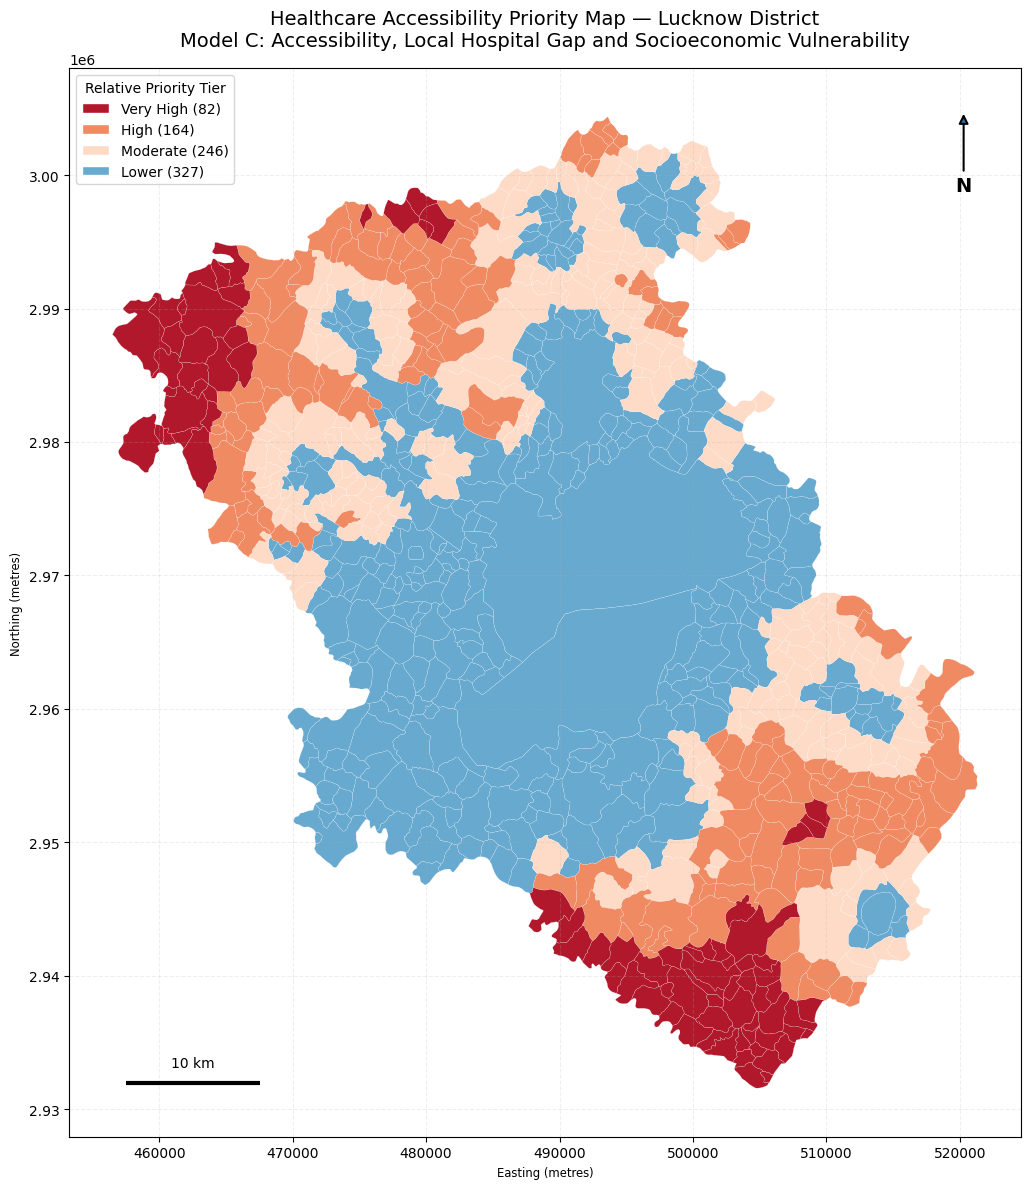


Map files saved:
/content/gdrive/MyDrive/lucknow_census_processed/lucknow_district_healthcare_priority_model_c.png
/content/gdrive/MyDrive/lucknow_census_processed/lucknow_district_healthcare_priority_model_c.pdf


In [ ]:

import os
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

base_dir = "/content/gdrive/MyDrive/lucknow_census_processed"

gpkg_path = os.path.join(
    base_dir,
    "lucknow_settlement_priority_model_c.gpkg"
)

gdf = gpd.read_file(
    gpkg_path,
    layer="settlement_priority_model_c"
)

# Project to UTM zone 44N for metric measurements
gdf_m = gdf.to_crs(epsg=32644)

tier_colors = {
    "Very High": "#b2182b",
    "High": "#ef8a62",
    "Moderate": "#fddbc7",
    "Lower": "#67a9cf"
}

fig, ax = plt.subplots(figsize=(12, 12))

# Plot lower priority first, highest priority last
for tier in ["Lower", "Moderate", "High", "Very High"]:
    subset = gdf_m[
        gdf_m["priority_tier_model_c"] == tier
    ]

    subset.plot(
        ax=ax,
        color=tier_colors[tier],
        edgecolor="white",
        linewidth=0.12
    )

ax.set_title(
    "Healthcare Accessibility Priority Map — Lucknow District\n"
    "Model C: Accessibility, Local Hospital Gap and "
    "Socioeconomic Vulnerability",
    fontsize=14,
    pad=16
)

ax.set_xlabel("Easting (metres)")
ax.set_ylabel("Northing (metres)")

# North arrow
ax.annotate(
    "N",
    xy=(0.94, 0.96),
    xytext=(0.94, 0.89),
    xycoords="axes fraction",
    textcoords="axes fraction",
    ha="center",
    va="center",
    fontsize=14,
    fontweight="bold",
    arrowprops=dict(arrowstyle="-|>", lw=1.5)
)

# Manual 10 km scale bar
xmin, xmax = ax.get_xlim()
ymin, ymax = ax.get_ylim()

bar_length = 10000  # metres
bar_x = xmin + 0.06 * (xmax - xmin)
bar_y = ymin + 0.05 * (ymax - ymin)

ax.plot(
    [bar_x, bar_x + bar_length],
    [bar_y, bar_y],
    color="black",
    linewidth=3,
    solid_capstyle="butt"
)

ax.text(
    bar_x + bar_length / 2,
    bar_y + 0.012 * (ymax - ymin),
    "10 km",
    ha="center",
    va="bottom",
    fontsize=10
)

# Legend with actual tier counts
legend_items = [
    Patch(
        facecolor=tier_colors[tier],
        edgecolor="white",
        label=f"{tier} ({int((gdf['priority_tier_model_c'] == tier).sum())})"
    )
    for tier in ["Very High", "High", "Moderate", "Lower"]
]

ax.legend(
    handles=legend_items,
    title="Relative Priority Tier",
    loc="upper left",
    frameon=True
)

ax.set_aspect("equal")
ax.grid(alpha=0.2, linestyle="--")
plt.tight_layout()

png_path = os.path.join(
    base_dir,
    "lucknow_district_healthcare_priority_model_c.png"
)

pdf_path = os.path.join(
    base_dir,
    "lucknow_district_healthcare_priority_model_c.pdf"
)

fig.savefig(png_path, dpi=300, bbox_inches="tight")
fig.savefig(pdf_path, bbox_inches="tight")
plt.show()

print("\nMap files saved:")
print(png_path)
print(pdf_path)


In [ ]:

import geopandas as gpd
import os

district_path = (
    "/content/gdrive/MyDrive/Lucknow_Census_Raw/2011_Dist.shp"
)

print("Shapefile exists:", os.path.exists(district_path))

districts = gpd.read_file(district_path)

print("\nNumber of features:", len(districts))
print("CRS:", districts.crs)

print("\nAvailable columns:")
print(districts.columns.tolist())

print("\nSample records:")
display(districts.drop(columns="geometry").head(10))

print("\nText columns and their unique-value samples:")
for col in districts.select_dtypes(include="object").columns:
    print(f"\n{col}")
    print(districts[col].dropna().astype(str).unique()[:20])


Shapefile exists: True

Number of features: 641
CRS: EPSG:4326

Available columns:
['DISTRICT', 'ST_NM', 'ST_CEN_CD', 'DT_CEN_CD', 'censuscode', 'geometry']

Sample records:


,DISTRICT,ST_NM,ST_CEN_CD,DT_CEN_CD,censuscode
0,Adilabad,Andhra Pradesh,28,1,532
1,Agra,Uttar Pradesh,9,15,146
2,Ahmadabad,Gujarat,24,7,474
3,Ahmadnagar,Maharashtra,27,26,522
4,Aizawl,Mizoram,15,3,283
5,Ajmer,Rajasthan,8,21,119
6,Akola,Maharashtra,27,5,501
7,Alappuzha,Kerala,32,11,598
8,Aligarh,Uttar Pradesh,9,12,143
9,Alirajpur,Madhya Pradesh,23,48,465



Text columns and their unique-value samples:

DISTRICT
['Adilabad' 'Agra' 'Ahmadabad' 'Ahmadnagar' 'Aizawl' 'Ajmer' 'Akola'
 'Alappuzha' 'Aligarh' 'Alirajpur' 'Allahabad' 'Almora' 'Alwar' 'Ambala'
 'Ambedkar Nagar' 'Amravati' 'Amreli' 'Amritsar' 'Anand' 'Anantapur']

ST_NM
['Andhra Pradesh' 'Uttar Pradesh' 'Gujarat' 'Maharashtra' 'Mizoram'
 'Rajasthan' 'Kerala' 'Madhya Pradesh' 'Uttarakhand' 'Haryana' 'Punjab'
 'Jammu & Kashmir' 'Arunanchal Pradesh' 'Odisha' 'Bihar' 'Tamil Nadu'
 'Karnataka' 'Assam' 'West Bengal' 'Chhattisgarh']


In [ ]:

import geopandas as gpd

district_path = (
    "/content/gdrive/MyDrive/Lucknow_Census_Raw/2011_Dist.shp"
)

districts = gpd.read_file(district_path)

# Select Lucknow district in Uttar Pradesh
lucknow_boundary = districts[
    (districts["DISTRICT"].str.strip().str.lower() == "lucknow") &
    (districts["ST_NM"].str.strip().str.lower() == "uttar pradesh")
].copy()

print("Matching district records:", len(lucknow_boundary))

if len(lucknow_boundary) != 1:
    print("Unexpected match count. Inspect matching records before proceeding.")
    display(
        districts[
            districts["DISTRICT"].str.contains(
                "lucknow", case=False, na=False
            )
        ].drop(columns="geometry")
    )
else:
    print("\nSelected district:")
    display(lucknow_boundary.drop(columns="geometry"))

    print("\nCRS:", lucknow_boundary.crs)
    print("Geometry type:", lucknow_boundary.geometry.geom_type.tolist())
    print("Geometry valid:", lucknow_boundary.geometry.is_valid.tolist())
    print("Bounds:", lucknow_boundary.total_bounds)

    # Reproject for comparison with the Model C map
    lucknow_boundary_m = lucknow_boundary.to_crs(epsg=32644)

    print("\nProjected bounds (UTM 44N):")
    print(lucknow_boundary_m.total_bounds)


Matching district records: 1

Selected district:


,DISTRICT,ST_NM,ST_CEN_CD,DT_CEN_CD,censuscode
344,Lucknow,Uttar Pradesh,9,26,157



CRS: EPSG:4326
Geometry type: ['Polygon']
Geometry valid: [True]
Bounds: [80.56048841 26.50150091 81.21900263 27.1589748 ]

Projected bounds (UTM 44N):
[ 456397.67950184 2931224.7003999   521784.6290856  3004045.33546279]


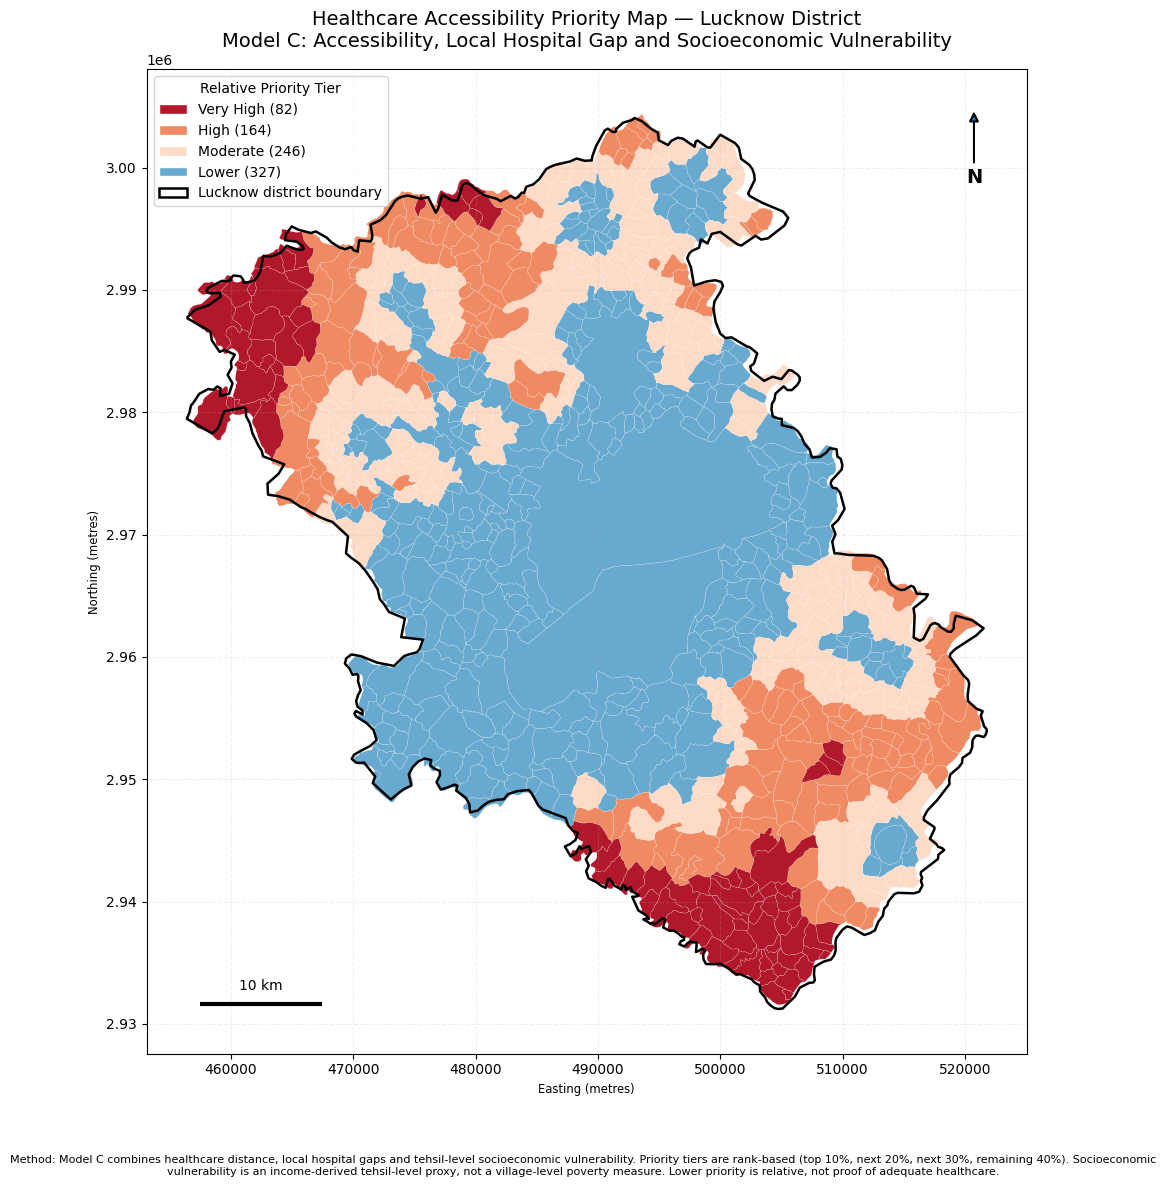


Final map files saved:
/content/gdrive/MyDrive/lucknow_census_processed/lucknow_district_healthcare_priority_model_c_final.png
/content/gdrive/MyDrive/lucknow_census_processed/lucknow_district_healthcare_priority_model_c_final.pdf

Settlement polygons: 819
District boundary features: 1


In [ ]:

import os
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

base_dir = "/content/gdrive/MyDrive/lucknow_census_processed"
district_path = (
    "/content/gdrive/MyDrive/Lucknow_Census_Raw/2011_Dist.shp"
)

# Load existing Model C settlement polygons
gdf = gpd.read_file(
    os.path.join(base_dir, "lucknow_settlement_priority_model_c.gpkg"),
    layer="settlement_priority_model_c"
)

# Select Lucknow district in Uttar Pradesh
districts = gpd.read_file(district_path)
lucknow = districts[
    (districts["DISTRICT"].str.strip().str.lower() == "lucknow") &
    (districts["ST_NM"].str.strip().str.lower() == "uttar pradesh")
].copy()

if len(lucknow) != 1:
    raise ValueError(
        f"Expected exactly one Lucknow district polygon; found {len(lucknow)}."
    )

# Use UTM Zone 44N for metric coordinates
gdf_m = gdf.to_crs(epsg=32644)
lucknow_m = lucknow.to_crs(epsg=32644)

# Priority tier colors
tier_colors = {
    "Very High": "#b2182b",
    "High": "#ef8a62",
    "Moderate": "#fddbc7",
    "Lower": "#67a9cf"
}

fig, ax = plt.subplots(figsize=(12, 12))

# Plot settlements, lower priority first
for tier in ["Lower", "Moderate", "High", "Very High"]:
    subset = gdf_m[gdf_m["priority_tier_model_c"] == tier]
    subset.plot(
        ax=ax,
        color=tier_colors[tier],
        edgecolor="white",
        linewidth=0.12,
        zorder=1
    )

# Draw the official-source district polygon outline on top
lucknow_m.boundary.plot(
    ax=ax,
    color="black",
    linewidth=1.8,
    zorder=5
)

# Title
ax.set_title(
    "Healthcare Accessibility Priority Map — Lucknow District\n"
    "Model C: Accessibility, Local Hospital Gap and "
    "Socioeconomic Vulnerability",
    fontsize=14,
    pad=16
)

ax.set_xlabel("Easting (metres)")
ax.set_ylabel("Northing (metres)")

# North arrow
ax.annotate(
    "N",
    xy=(0.94, 0.96),
    xytext=(0.94, 0.89),
    xycoords="axes fraction",
    textcoords="axes fraction",
    ha="center",
    va="center",
    fontsize=14,
    fontweight="bold",
    arrowprops=dict(arrowstyle="-|>", lw=1.5)
)

# Manual scale bar: 10 km
xmin, xmax = ax.get_xlim()
ymin, ymax = ax.get_ylim()
bar_length = 10000
bar_x = xmin + 0.06 * (xmax - xmin)
bar_y = ymin + 0.05 * (ymax - ymin)

ax.plot(
    [bar_x, bar_x + bar_length],
    [bar_y, bar_y],
    color="black",
    linewidth=3,
    solid_capstyle="butt",
    zorder=6
)
ax.text(
    bar_x + bar_length / 2,
    bar_y + 0.012 * (ymax - ymin),
    "10 km",
    ha="center",
    va="bottom",
    fontsize=10
)

# Legend
legend_items = [
    Patch(
        facecolor=tier_colors[tier],
        edgecolor="white",
        label=f"{tier} ({int((gdf['priority_tier_model_c'] == tier).sum())})"
    )
    for tier in ["Very High", "High", "Moderate", "Lower"]
]

legend_items.append(
    Patch(
        facecolor="none",
        edgecolor="black",
        linewidth=1.8,
        label="Lucknow district boundary"
    )
)

ax.legend(
    handles=legend_items,
    title="Relative Priority Tier",
    loc="upper left",
    frameon=True
)

# Methodology note
method_note = (
    "Method: Model C combines healthcare distance, local hospital gaps "
    "and tehsil-level socioeconomic vulnerability. "
    "Priority tiers are rank-based (top 10%, next 20%, next 30%, "
    "remaining 40%). Socioeconomic vulnerability is an income-derived "
    "tehsil-level proxy, not a village-level poverty measure. "
    "Lower priority is relative, not proof of adequate healthcare."
)

fig.text(
    0.5, 0.015,
    method_note,
    ha="center",
    va="bottom",
    fontsize=8,
    wrap=True
)

ax.set_aspect("equal")
ax.grid(alpha=0.2, linestyle="--")
plt.tight_layout(rect=[0, 0.07, 1, 1])

png_path = os.path.join(
    base_dir,
    "lucknow_district_healthcare_priority_model_c_final.png"
)
pdf_path = os.path.join(
    base_dir,
    "lucknow_district_healthcare_priority_model_c_final.pdf"
)

fig.savefig(png_path, dpi=300, bbox_inches="tight")
fig.savefig(pdf_path, bbox_inches="tight")
plt.show()

print("\nFinal map files saved:")
print(png_path)
print(pdf_path)
print("\nSettlement polygons:", len(gdf_m))
print("District boundary features:", len(lucknow_m))


In [ ]:

import os
import pandas as pd

base_dir = "/content/gdrive/MyDrive/lucknow_census_processed"

input_path = os.path.join(
    base_dir,
    "lucknow_settlement_priority_scores_model_c.csv"
)

df = pd.read_csv(input_path)

# Summarize priority distribution by tehsil
tier_order = ["Very High", "High", "Moderate", "Lower"]

summary = (
    df.groupby("tehsil_name")
      .agg(
          settlements=("pc11_tv_id", "count"),
          population=("population_corrected", "sum"),
          mean_priority_score=("priority_score_model_c", "mean"),
          mean_nearest_hospital_distance_km=(
              "nearest_hospital_distance_km", "mean"
          ),
          settlements_without_local_hospital=(
              "hospital_record_count",
              lambda s: (s.fillna(0) == 0).sum()
          )
      )
      .reset_index()
)

tier_counts = pd.crosstab(
    df["tehsil_name"],
    df["priority_tier_model_c"]
)

for tier in tier_order:
    summary[tier.lower().replace(" ", "_") + "_count"] = (
        summary["tehsil_name"]
        .map(tier_counts[tier] if tier in tier_counts.columns
             else pd.Series(dtype=float))
        .fillna(0)
        .astype(int)
    )

summary["mean_priority_score"] = summary["mean_priority_score"].round(2)
summary["mean_nearest_hospital_distance_km"] = (
    summary["mean_nearest_hospital_distance_km"].round(2)
)

output_path = os.path.join(
    base_dir,
    "lucknow_model_c_tehsil_dashboard_summary.csv"
)

summary.to_csv(output_path, index=False)

print("Summary saved to:", output_path)
display(summary)


Summary saved to: /content/gdrive/MyDrive/lucknow_census_processed/lucknow_model_c_tehsil_dashboard_summary.csv


,tehsil_name,settlements,population,mean_priority_score,mean_nearest_hospital_distance_km,settlements_without_local_hospital,very_high_count,high_count,moderate_count,lower_count
0,Bakshi Ka Talab,189,349654.0,54.84,3.31,178,0,22,94,73
1,Lucknow (Sadar),210,3391208.0,37.46,2.71,180,0,0,7,203
2,Malihabad,188,368453.0,65.06,5.28,185,30,67,69,22
3,Mohanlalganj,232,480523.0,65.70,5.82,224,52,75,76,29


In [ ]:

import os
import pandas as pd

base_dir = "/content/gdrive/MyDrive/lucknow_census_processed"

input_path = os.path.join(
    base_dir,
    "lucknow_settlement_priority_scores_model_c.csv"
)

df = pd.read_csv(input_path)

tier_order = ["Very High", "High", "Moderate", "Lower"]

# District-wide KPIs
kpis = {
    "total_settlements": len(df),
    "represented_population": df["population_corrected"].sum(),
    "mean_priority_score": df["priority_score_model_c"].mean(),
    "mean_nearest_hospital_distance_km":
        df["nearest_hospital_distance_km"].mean(),
    "settlements_without_local_hospital_record":
        (df["hospital_record_count"].fillna(0) == 0).sum()
}

for tier in tier_order:
    kpis[f"{tier.lower().replace(' ', '_')}_settlements"] = (
        df["priority_tier_model_c"] == tier
    ).sum()

kpi_df = pd.DataFrame(
    [{"indicator": key, "value": value}
     for key, value in kpis.items()]
)

output_path = os.path.join(
    base_dir,
    "lucknow_model_c_dashboard_kpis.csv"
)

kpi_df.to_csv(output_path, index=False)

print("Dashboard KPI summary saved:", output_path)
display(kpi_df)


Dashboard KPI summary saved: /content/gdrive/MyDrive/lucknow_census_processed/lucknow_model_c_dashboard_kpis.csv


,indicator,value
0,total_settlements,8.190000e+02
1,represented_population,4.589838e+06
2,mean_priority_score,5.580630e+01
3,mean_nearest_hospital_distance_km,4.317899e+00
4,settlements_without_local_hospital_record,7.670000e+02
5,very_high_settlements,8.200000e+01
6,high_settlements,1.640000e+02
7,moderate_settlements,2.460000e+02
8,lower_settlements,3.270000e+02


In [ ]:
import os
import pandas as pd

BASE = "/content/gdrive/MyDrive/lucknow_census_processed"

files = [
    "lucknow_ward_socioeconomic_vulnerability_2012.csv",
    "lucknow_urban_healthcare_priority_scores_model_c.csv",
]

for filename in files:
    path = os.path.join(BASE, filename)

    print(f"\n{'=' * 60}")
    print(filename)

    if os.path.exists(path):
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        print(df.head(3).to_string(index=False))
    else:
        print("FILE NOT FOUND")


lucknow_ward_socioeconomic_vulnerability_2012.csv
Shape: (110, 7)
Columns: ['map_unit_id', 'Ward Name', 'ward_num', 'population_2012', 'per_capita_income_2012_inr', 'prosperity_index_2012', 'socioeconomic_vulnerability_score']
map_unit_id            Ward Name  ward_num  population_2012  per_capita_income_2012_inr  prosperity_index_2012  socioeconomic_vulnerability_score
    LMC_004 Sarojni Nagar Part 1         4            25432                       43240                   1358                              92.86
    LMC_015 Sarojni Nagar Part 2        15            47513                       62358                   1959                              79.25
    LMC_002      Raja Bijli Pasi         2            43931                       66396                   2086                              76.38

lucknow_urban_healthcare_priority_scores_model_c.csv
Shape: (111, 23)
Columns: ['map_unit_id', 'map_unit_type', 'map_unit_name', 'total_population', 'hospital_records', 'public_hospitals'

In [ ]:
import os
import pandas as pd

BASE = "/content/gdrive/MyDrive/lucknow_census_processed"

socio_path = os.path.join(
    BASE, "lucknow_ward_socioeconomic_vulnerability_2012.csv"
)
model_path = os.path.join(
    BASE, "lucknow_urban_healthcare_priority_scores_model_c.csv"
)

socio = pd.read_csv(socio_path)
model = pd.read_csv(model_path)

# Existing LMC income range
income_col = "per_capita_income_2012_inr"
income_min = socio[income_col].min()
income_max = socio[income_col].max()

print("LMC minimum per-capita income:", income_min)
print("LMC maximum per-capita income:", income_max)

# Cantonment row in the urban model
cant = model[
    model["map_unit_type"].astype(str).str.contains(
        "CANT", case=False, na=False
    )
    | model["map_unit_name"].astype(str).str.contains(
        "CANTONMENT", case=False, na=False
    )
]

print("\nCantonment rows found:", len(cant))
print(cant.to_string(index=False))

# Calculate the proposed vulnerability for ₹80,072
income_cant = 80072
vulnerability_cant = (
    100 * (income_max - income_cant) / (income_max - income_min)
)

print("\nProposed Cantonment income:", income_cant)
print("Proposed Cantonment vulnerability:", round(vulnerability_cant, 2))

LMC minimum per-capita income: 33198
LMC maximum per-capita income: 173754

Cantonment rows found: 1
map_unit_id        map_unit_type      map_unit_name  total_population  hospital_records  public_hospitals  private_hospitals  beds_total  nearest_hospital_distance_km  distance_score  population_score  bed_shortage_score  hospital_gap_score  combined_availability_gap  public_gap_score  priority_score_model_b  priority_rank_model_b priority_tier_model_b  socioeconomic_vulnerability_score  priority_score_model_c                    socioeconomic_data_status  priority_rank_model_c priority_tier_model_c
 CANTONMENT CANTONMENT_AGGREGATE Lucknow Cantonment             63003                 3                 3                  0      1372.0                      1.344972       97.297297         99.099099            4.504505           45.045045                  24.774775          3.603604               59.279279                     39              Moderate                                NaN      

In [ ]:
# Existing Cantonment component scores
D = 97.297297
P = 99.099099
A = 24.774775
G = 3.603604

# Income-derived vulnerability, calculated using full precision
income_cant = 80072
income_min = 33198
income_max = 173754

S_exact = 100 * (income_max - income_cant) / (income_max - income_min)

# Apply the same Model formula
score_cant_new = (
    0.25 * D
    + 0.15 * P
    + 0.35 * A
    + 0.10 * G
    + 0.15 * S_exact
)

print(f"Cantonment income: ₹{income_cant:,}")
print(f"Socioeconomic vulnerability: {S_exact:.4f}")
print(f"Previous Model score: 56.7303")
print(f"Updated Model score: {score_cant_new:.4f}")
print(f"Score change: {score_cant_new - 56.7303:+.4f}")

Cantonment income: ₹80,072
Socioeconomic vulnerability: 66.6510
Previous Model score: 56.7303
Updated Model score: 58.2184
Score change: +1.4881


In [ ]:
import os
import numpy as np
import pandas as pd

BASE = "/content/gdrive/MyDrive/lucknow_census_processed"

socio_path = os.path.join(
    BASE, "lucknow_ward_socioeconomic_vulnerability_2012.csv"
)
model_path = os.path.join(
    BASE, "lucknow_urban_healthcare_priority_scores_model_c.csv"
)

socio = pd.read_csv(socio_path)
model = pd.read_csv(model_path)

# --------------------------------------------------
# 1. Define the manually researched Cantonment income
# --------------------------------------------------
CANT_ID = "CANTONMENT"
CANT_INCOME = 80072

income_col = "per_capita_income_2012_inr"
income_min = socio[income_col].min()
income_max = socio[income_col].max()

cant_vulnerability = (
    100 * (income_max - CANT_INCOME) / (income_max - income_min)
)

# --------------------------------------------------
# 2. Add Cantonment to the socioeconomic dataset
# --------------------------------------------------
cant_socio = pd.DataFrame([{
    "map_unit_id": CANT_ID,
    "Ward Name": "Lucknow Cantonment",
    "ward_num": np.nan,
    "population_2012": 63003,
    "per_capita_income_2012_inr": CANT_INCOME,
    "prosperity_index_2012": np.nan,
    "socioeconomic_vulnerability_score": round(
        cant_vulnerability, 2
    )
}])

socio_updated = socio[socio["map_unit_id"] != CANT_ID].copy()
socio_updated = pd.concat(
    [socio_updated, cant_socio], ignore_index=True
)

# --------------------------------------------------
# 3. Update Cantonment only in the Model scores
# --------------------------------------------------
cant_mask = model["map_unit_id"].eq(CANT_ID)

if cant_mask.sum() != 1:
    raise ValueError(
        f"Expected exactly one Cantonment row; found {cant_mask.sum()}"
    )

model_updated = model.copy()

model_updated.loc[
    cant_mask, "socioeconomic_vulnerability_score"
] = cant_vulnerability

# Same Model formula: 0.25D + 0.15P + 0.35A + 0.10G + 0.15S
model_updated.loc[cant_mask, "priority_score_model_c"] = (
    0.25 * model_updated.loc[cant_mask, "distance_score"]
    + 0.15 * model_updated.loc[cant_mask, "population_score"]
    + 0.35 * model_updated.loc[cant_mask, "combined_availability_gap"]
    + 0.10 * model_updated.loc[cant_mask, "public_gap_score"]
    + 0.15 * model_updated.loc[
        cant_mask, "socioeconomic_vulnerability_score"
    ]
)

model_updated.loc[
    cant_mask, "socioeconomic_data_status"
] = "Available; manually sourced income ₹80,072"

# --------------------------------------------------
# 4. Recompute ranks for all units
# --------------------------------------------------
model_updated["priority_rank_model_c"] = (
    model_updated["priority_score_model_c"]
    .rank(method="min", ascending=False)
    .astype(int)
)

# Preserve the existing tiering rule by examining its
# original rank boundaries before changing tier labels.
original = pd.read_csv(model_path)
original["priority_rank_model_c"] = pd.to_numeric(
    original["priority_rank_model_c"], errors="coerce"
)

tier_bounds = (
    original.groupby("priority_tier_model_c")[
        "priority_rank_model_c"
    ]
    .agg(["min", "max"])
    .to_dict("index")
)

print("Original tier rank boundaries:", tier_bounds)

# Use the original score thresholds where they can be recovered
# from the original model. This avoids silently changing tier logic.
for tier in ["Very High", "High", "Moderate", "Lower"]:
    old_scores = original.loc[
        original["priority_tier_model_c"].eq(tier),
        "priority_score_model_c"
    ].dropna()

    if not old_scores.empty:
        print(
            f"{tier}: original score range "
            f"{old_scores.min():.4f}–{old_scores.max():.4f}"
        )

# --------------------------------------------------
# 5. Save as new files, not over the originals
# --------------------------------------------------
socio_out = os.path.join(
    BASE, "lucknow_urban_socioeconomic_vulnerability_2012_updated.csv"
)
model_out = os.path.join(
    BASE, "lucknow_urban_healthcare_priority_scores_model_c_updated.csv"
)

socio_updated.to_csv(socio_out, index=False)
model_updated.to_csv(model_out, index=False)

print("\nSaved updated files:")
print(socio_out)
print(model_out)

print("\nCantonment updated row:")
print(
    model_updated.loc[
        cant_mask,
        [
            "map_unit_id",
            "map_unit_name",
            "socioeconomic_vulnerability_score",
            "priority_score_model_c",
            "priority_rank_model_c",
            "socioeconomic_data_status"
        ]
    ].to_string(index=False)
)

print("\nUnit count:", len(model_updated))
print("Other 110 Model scores unchanged:",
      np.allclose(
          model_updated.loc[~cant_mask, "priority_score_model_c"],
          model.loc[~cant_mask, "priority_score_model_c"],
          equal_nan=True
      ))

Original tier rank boundaries: {'High': {'min': 13, 'max': 34}, 'Lower': {'min': 68, 'max': 111}, 'Moderate': {'min': 35, 'max': 67}, 'Very High': {'min': 1, 'max': 12}}
Very High: original score range 72.2244–79.9087
High: original score range 62.3616–71.1898
Moderate: original score range 48.1915–62.0055
Lower: original score range 11.8233–48.0412

Saved updated files:
/content/gdrive/MyDrive/lucknow_census_processed/lucknow_urban_socioeconomic_vulnerability_2012_updated.csv
/content/gdrive/MyDrive/lucknow_census_processed/lucknow_urban_healthcare_priority_scores_model_c_updated.csv

Cantonment updated row:
map_unit_id      map_unit_name  socioeconomic_vulnerability_score  priority_score_model_c  priority_rank_model_c                  socioeconomic_data_status
 CANTONMENT Lucknow Cantonment                          66.651015               58.218373                     45 Available; manually sourced income ₹80,072

Unit count: 111
Other 110 Model scores unchanged: True


In [ ]:
import os
import pandas as pd

BASE = "/content/gdrive/MyDrive/lucknow_census_processed"

model_path = os.path.join(
    BASE,
    "lucknow_urban_healthcare_priority_scores_model_c_updated.csv"
)

model = pd.read_csv(model_path)

# Preserve the original Model score thresholds
conditions = [
    model["priority_score_model_c"] >= 72.2244,
    (model["priority_score_model_c"] >= 62.3616)
        & (model["priority_score_model_c"] < 72.2244),
    (model["priority_score_model_c"] >= 48.1915)
        & (model["priority_score_model_c"] < 62.3616),
    model["priority_score_model_c"] < 48.1915
]

tiers = ["Very High", "High", "Moderate", "Lower"]

model["priority_tier_model_c"] = pd.Series(
    pd.NA, index=model.index, dtype="object"
)

for condition, tier in zip(conditions, tiers):
    model.loc[condition, "priority_tier_model_c"] = tier

# Save the corrected updated model file
model.to_csv(model_path, index=False)

print("Priority tier counts:")
print(
    model["priority_tier_model_c"]
    .value_counts()
    .reindex(tiers, fill_value=0)
    .to_string()
)

print("\nCantonment final status:")
print(
    model.loc[
        model["map_unit_id"].eq("CANTONMENT"),
        [
            "map_unit_name",
            "socioeconomic_vulnerability_score",
            "priority_score_model_c",
            "priority_rank_model_c",
            "priority_tier_model_c",
            "socioeconomic_data_status"
        ]
    ].to_string(index=False)
)

Priority tier counts:
priority_tier_model_c
Very High    11
High         23
Moderate     32
Lower        45

Cantonment final status:
     map_unit_name  socioeconomic_vulnerability_score  priority_score_model_c  priority_rank_model_c priority_tier_model_c                  socioeconomic_data_status
Lucknow Cantonment                          66.651015               58.218373                     45              Moderate Available; manually sourced income ₹80,072


In [ ]:
import os
import pandas as pd

BASE = "/content/gdrive/MyDrive/lucknow_census_processed"

model_path = os.path.join(
    BASE,
    "lucknow_urban_healthcare_priority_scores_model_c_updated.csv"
)

model = pd.read_csv(model_path)

# Recalculate ranks from the updated Model scores
model["priority_rank_model_c"] = (
    model["priority_score_model_c"]
    .rank(method="first", ascending=False)
    .astype(int)
)

# Apply the original rank-based tier bands
def assign_tier(rank):
    if rank <= 12:
        return "Very High"
    elif rank <= 34:
        return "High"
    elif rank <= 67:
        return "Moderate"
    else:
        return "Lower"

model["priority_tier_model_c"] = (
    model["priority_rank_model_c"].apply(assign_tier)
)

model.to_csv(model_path, index=False)

print("Updated tier counts:")
print(
    model["priority_tier_model_c"]
    .value_counts()
    .reindex(["Very High", "High", "Moderate", "Lower"], fill_value=0)
)

print("\nCantonment:")
print(
    model.loc[
        model["map_unit_id"] == "CANTONMENT",
        [
            "map_unit_name",
            "priority_score_model_c",
            "priority_rank_model_c",
            "priority_tier_model_c"
        ]
    ].to_string(index=False)
)

print("\nSaved:", model_path)

Updated tier counts:
priority_tier_model_c
Very High    12
High         22
Moderate     33
Lower        44
Name: count, dtype: int64

Cantonment:
     map_unit_name  priority_score_model_c  priority_rank_model_c priority_tier_model_c
Lucknow Cantonment               58.218373                     45              Moderate

Saved: /content/gdrive/MyDrive/lucknow_census_processed/lucknow_urban_healthcare_priority_scores_model_c_updated.csv


In [ ]:

from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import pandas as pd
from datetime import datetime

# Your processed data folder
BASE = Path("/content/drive/MyDrive/lucknow_census_processed")

if not BASE.exists():
    raise FileNotFoundError(f"Folder not found: {BASE}")

records = []

for path in sorted(BASE.rglob("*")):
    if path.is_file():
        stat = path.stat()
        records.append({
            "file_name": path.name,
            "relative_path": str(path.relative_to(BASE)),
            "extension": path.suffix.lower() or "[no extension]",
            "size_MB": round(stat.st_size / (1024 * 1024), 3),
            "last_modified": datetime.fromtimestamp(
                stat.st_mtime
            ).strftime("%Y-%m-%d %H:%M:%S")
        })

files_df = pd.DataFrame(records)

print(f"Total files: {len(files_df)}")
print(f"Total size: {files_df['size_MB'].sum():.2f} MB")
print("\nFILES IN PROCESSED FOLDER\n")

if not files_df.empty:
    display(files_df)
else:
    print("No files found.")


Mounted at /content/drive
Total files: 287
Total size: 277.91 MB

FILES IN PROCESSED FOLDER



,file_name,relative_path,extension,size_MB,last_modified
0,DH_2011_0926_PART_A_DCHB_LUCKNOW_extracted.txt,DH_2011_0926_PART_A_DCHB_LUCKNOW_extracted.txt,.txt,0.837,2026-10-23 08:40:30
1,DH_2011_0926_PART_B_DCHB_LUCKNOW_extracted.txt,DH_2011_0926_PART_B_DCHB_LUCKNOW_extracted.txt,.txt,0.877,2026-10-23 08:41:36
2,Appendix_IA_0926__Sheet1.csv,census_appendices_raw_csv/Appendix_IA_0926__Sh...,.csv,0.001,2026-10-23 08:40:07
3,Appendix_IB_0926__Sheet1.csv,census_appendices_raw_csv/Appendix_IB_0926__Sh...,.csv,0.001,2026-10-23 08:40:07
4,Appendix_IC_0926__Sheet1.csv,census_appendices_raw_csv/Appendix_IC_0926__Sh...,.csv,0.001,2026-10-23 08:40:07
...,...,...,...,...,...
282,wards_lucknow.dbf,ward_boundaries_candidate/wards_lucknow.dbf,.dbf,0.012,2026-10-23 20:51:05
283,wards_lucknow.prj,ward_boundaries_candidate/wards_lucknow.prj,.prj,0.000,2026-10-23 20:51:05
284,wards_lucknow.shp,ward_boundaries_candidate/wards_lucknow.shp,.shp,0.131,2026-10-23 20:51:05
285,wards_lucknow.shx,ward_boundaries_candidate/wards_lucknow.shx,.shx,0.001,2026-10-23 20:51:05


In [ ]:

inventory_path = BASE / "processed_folder_inventory.csv"

files_df.to_csv(inventory_path, index=False)

print("Inventory saved to:")
print(inventory_path)

print(f"\nTotal files inventoried: {len(files_df)}")


Inventory saved to:
/content/drive/MyDrive/lucknow_census_processed/processed_folder_inventory.csv

Total files inventoried: 287


In [ ]:
from google.colab import files

files.download(
    "/content/drive/MyDrive/lucknow_census_processed/processed_folder_inventory.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>